# Objetivo específico 1 — Dataset, ETL, análisis exploratorio e ingeniería de características

**Proyecto de grado:** Modelo analítico para la detección de comportamientos atípicos de funcionarios en la aprobación de créditos del sector financiero privado colombiano (Especialización en Analítica de Datos, CUN).  
**Autores:** Ángel Antonio Rodríguez Goyo, Julio Cesar Sánchez Jiménez y Gladys Dalexa Picón Solano. **Tutor:** Andrés Felipe Solís Pino.  
**Versión del código:** v0.2 · **Semilla:** 42 · **Fase CRISP-DM:** comprensión de los datos y preparación de los datos (fases 2 y 3).

Este cuaderno reproduce todo lo que respalda el capítulo 8 del informe (*Desarrollo de las fases del proyecto*, fases 1 a 3). Se ejecuta con **Entorno de ejecución → Ejecutar todo** y solo necesita el repositorio.

| Sección | Qué produce | Salida |
|---|---|---|
| 0 | Entorno, semilla y rutas | `results/resultados_obj1.json` (entorno) |
| 1 | Adquisición y verificación de integridad del dataset | `data/raw/adquisicion.json` |
| 2 | Ficha del dataset | `docs/tablas/tabla_ficha_dataset.csv` |
| 3 | Diccionario de datos | `docs/tablas/tabla_diccionario_datos.csv` |
| 4 | ETL con conteos antes y después | `data/processed/*.csv`, tablas 4.x |
| 5 | Análisis exploratorio univariado | figuras 5.x |
| 6 | Análisis exploratorio multivariado (variable objetivo, Pearson, Spearman, VIF, tendencia y estacionariedad, desbalance) | figuras 6.x |
| 7 | Ingeniería de características (solicitud y funcionario) | `data/processed/matriz_solicitud.csv`, `perfil_funcionario.csv` |
| 8 | Protocolo de evaluación | `docs/tablas/tabla_protocolo_evaluacion.csv` |
| 9 | Bitácora de decisiones | `docs/tablas/tabla_bitacora_decisiones.csv` |
| 10 | Verificaciones finales y huellas SHA-256 | `results/resultados_obj1.json` |

**Uso de las etiquetas.** Las columnas `es_anomalia` y `tipo_anomalia` se separan de los datos en la sección 4. Solo se usan para describir el dataset (por ejemplo, ver cómo se distribuyen) y, más adelante, para evaluar los modelos del objetivo 2; nunca para elegir variables ni ajustar parámetros.

**Pasos que quedan para el objetivo 2.** Rellenar vacíos, poner las variables en la misma escala y convertir las categorías en números no se hace aquí. Se hará en el objetivo 2, dentro de un `Pipeline` de scikit-learn y solo con los datos de entrenamiento, para que el modelo no vea información de la prueba.

## 0. Entorno, semilla y rutas

In [1]:
import os, sys, json, hashlib, random, platform, subprocess, unicodedata, warnings, pathlib, textwrap
import datetime as dt

# ------------------------------------------------------------------
# CONFIGURACIÓN (única celda que el usuario puede necesitar editar)
# ------------------------------------------------------------------
REPO_URL = "https://github.com/<USUARIO>/<REPOSITORIO>.git"   # <- reemplazar al publicar el repositorio
SEED = 42                                                      # semilla fija de todo el cuaderno
# ------------------------------------------------------------------

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and not pathlib.Path("src/features.py").exists():
    if "<USUARIO>" in REPO_URL:
        raise SystemExit("Edite REPO_URL con la dirección del repositorio de GitHub, o suba la carpeta del proyecto al entorno de Colab.")
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "proyecto"], check=True)
    os.chdir("proyecto")
elif not pathlib.Path("src/features.py").exists() and pathlib.Path("../src/features.py").exists():
    os.chdir("..")                      # ejecución local desde la carpeta notebooks/

ROOT = pathlib.Path.cwd()
RAW = ROOT / "data" / "raw"; PROC = ROOT / "data" / "processed"
FIG = ROOT / "docs" / "figuras"; TAB = ROOT / "docs" / "tablas"; RES = ROOT / "results"
for p in (RAW, PROC, FIG, TAB, RES):
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, scipy, sklearn, statsmodels, matplotlib, seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_columns", 50, "display.width", 160)

RESULTADOS = {"version_codigo": "v0.2", "semilla": SEED, "interpretaciones": {}}
RESULTADOS["entorno"] = {m.__name__: m.__version__ for m in (np, pd, scipy, sklearn, statsmodels, matplotlib, sns)}
RESULTADOS["entorno"]["python"] = platform.python_version()

# ---- utilidades de presentación (formato numérico en español) ----
def n(x, d=0):
    s = f"{x:,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")
def pct(x, d=1):
    return n(100 * x, d) + " %"

# ---- estilo de figuras (paleta categórica validada: azul, naranja, aguamarina) ----
AZUL, NARANJA, AGUA, AMARILLO, GRIS, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8f8f8a", "#222222"
CMAP_DIV = LinearSegmentedColormap.from_list("div", [AZUL, "#f2f2f0", NARANJA])
plt.rcParams.update({
    "font.size": 7.5, "axes.titlesize": 8.5, "axes.titleweight": "bold", "axes.labelsize": 7.5, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8f8f8a",
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight", "figure.facecolor": "white",
    "axes.facecolor": "white", "legend.frameon": False, "text.color": TINTA, "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA,
})

def guardar_fig(fig, nombre):
    ruta = FIG / f"{nombre}.png"
    fig.savefig(ruta); plt.show()
    return ruta

def guardar_tabla(df, nombre, indice=False):
    df.to_csv(TAB / f"{nombre}.csv", index=indice, encoding="utf-8-sig")
    return TAB / f"{nombre}.csv"

def interpretar(clave, titulo, frases):
    """Muestra el título y 2-3 frases de interpretación generadas con los resultados (nada se escribe a mano)."""
    texto = " ".join(frases)
    RESULTADOS["interpretaciones"][clave] = {"titulo": titulo, "texto": texto}
    display(Markdown(f"**{titulo}.** {texto}"))

print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("Directorio del proyecto:", ROOT)

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1
Directorio del proyecto: /home/claude/work/repo


## 1. Adquisición del dataset

**Fuente.** El dataset es **sintético**: lo genera el script `src/generar_dataset.py` con semilla 42 a partir de los parámetros descritos en el apartado 7.4 del informe. No se usó un conjunto de `datos.gov.co` porque no existen datos públicos de fraude interno en la aprobación de créditos (Phua et al., 2010, pp. 3-4).

**Copia de trabajo.** El archivo original está en `data/raw/` y se protege con una huella SHA-256 (`data/raw/SHA256SUMS.txt`). Si el archivo no está presente, el cuaderno lo regenera con la misma semilla y comprueba que el resultado sea idéntico al original.

In [2]:
CSV_RAW = RAW / "dataset_creditos_sinteticos.csv"
HASH_ESPERADO = (RAW / "SHA256SUMS.txt").read_text().split()[0]
FECHA_CORTE = "2026-09-10"   # fecha de corte del generador; la usa la regla de coherencia sobre fechas de solicitud

def sha256(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()

regenerado = False
if not CSV_RAW.exists():
    subprocess.run([sys.executable, "src/generar_dataset.py", "--salida", str(RAW)], check=True)
    regenerado = True

hash_obtenido = sha256(CSV_RAW)
assert hash_obtenido == HASH_ESPERADO, "La huella SHA-256 no coincide con la del dataset original."

raw = pd.read_csv(CSV_RAW, encoding="utf-8-sig")        # lectura SIN conversiones: es el estado "antes" del ETL
adquisicion = {
    "archivo": CSV_RAW.name, "tipo_fuente": "sintético (generador propio, semilla 42)",
    "regenerado_en_esta_ejecucion": regenerado,
    "sha256": hash_obtenido, "sha256_coincide_con_el_original": hash_obtenido == HASH_ESPERADO,
    "bytes": CSV_RAW.stat().st_size, "filas": int(raw.shape[0]), "columnas": int(raw.shape[1]),
    "codificacion": "UTF-8 con BOM", "separador": ",",
}
(RAW / "adquisicion.json").write_text(json.dumps(adquisicion, indent=2, ensure_ascii=False), encoding="utf-8")
RESULTADOS["adquisicion"] = adquisicion
display(pd.Series(adquisicion, name="valor").to_frame())

,valor
archivo,dataset_creditos_sinteticos.csv
tipo_fuente,"sintético (generador propio, semilla 42)"
regenerado_en_esta_ejecucion,False
sha256,e6ea48197a9ae79a2df458b26f686201b46759bcfdb4bc...
sha256_coincide_con_el_original,True
bytes,1989601
filas,9500
columnas,32
codificacion,UTF-8 con BOM
separador,","


### Cómo se genera el dataset

El script `src/generar_dataset.py` construye los datos en siete bloques, con la semilla 42:

1. Variables demográficas y socioeconómicas (edad, ingreso, gastos, tipo de empleo, entre otras).
2. Variables crediticias (score, historial, nivel de endeudamiento, monto y plazo solicitados, entre otras).
3. Variables organizacionales (funcionario, canal, región, fecha de la solicitud, excepciones, estado de aprobación y tiempo de respuesta).
4. Anomalías controladas, definidas así: **monto desproporcionado**, que multiplica el ingreso por un valor entre 25 y 60 (con tope de 100 millones de pesos); **funcionario con aprobación atípica**, que elige seis funcionarios (el 3 % de 220) y aprueba sus solicitudes con probabilidad de 95 % y con excepción con probabilidad de 50 %; y **tiempo de respuesta excesivo**, entre 35 y 69 días.
5. Conteo de créditos aprobados por funcionario.
6. Ensamblado de la tabla final, mezcla de las filas y renumeración.
7. Exportación a CSV.

El tipo «funcionario con aprobación atípica» no usa la muestra al azar que el bloque 4 separa para él (`idx_funcionario`): se define por funcionario, modificando todas las solicitudes de los seis elegidos.

Las dos celdas siguientes muestran los parámetros y el código de las anomalías tal como están en el script, y comprueban que ejecutarlo de nuevo reproduce el archivo original.

In [3]:
# Parámetros y bloque de anomalías del generador (se leen del propio script)
codigo = (ROOT / "src" / "generar_dataset.py").read_text(encoding="utf-8").splitlines()

def tramo(inicio, fin):
    i = next(k for k, l in enumerate(codigo) if inicio in l)
    j = next(k for k, l in enumerate(codigo) if fin in l and k > i)
    return "\n".join(codigo[i:j - 1])

print("--- Parámetros generales ---")
print(tramo("SEED = 42", "# Utilidades"))
print("\n--- Bloque 4: inyección de anomalías controladas ---")
print(tramo("n_anom = int", "# 5. Número de créditos"))

--- Parámetros generales ---
SEED = 42
rng = np.random.default_rng(SEED)

N = 9500                 # dentro del rango 9.000-10.000 registros
N_FUNCIONARIOS = 220      # número de funcionarios evaluadores
TASA_ANOMALIAS = 0.08     # 8%, dentro del rango 5-10% pedido


--- Bloque 4: inyección de anomalías controladas ---
n_anom = int(round(N * TASA_ANOMALIAS))
anomaly_idx = rng.choice(N, size=n_anom, replace=False)
# Dividir las anomalías en 3 arquetipos, según el procedimiento de generación
tercio = n_anom // 3
idx_monto = anomaly_idx[:tercio]
# Nota: esta muestra no se usa; el tipo "funcionario con aprobación atípica" se define por funcionario, en el bloque (b).
idx_funcionario = anomaly_idx[tercio:2 * tercio]
idx_tiempo = anomaly_idx[2 * tercio:]

es_anomalia = np.zeros(N, dtype=int)
tipo_anomalia = np.full(N, "Ninguna", dtype=object)

# (a) Montos desproporcionados respecto al ingreso
monto_solicitado[idx_monto] = clip(
    ingreso_mensual[idx_monto] * rng.uniform(25, 60, len(idx_mon

In [4]:
import tempfile

# Se regenera en una carpeta temporal: el archivo original de data/raw no se toca
with tempfile.TemporaryDirectory() as tmp:
    subprocess.run([sys.executable, "src/generar_dataset.py", "--salida", tmp],
                   check=True, capture_output=True)
    hash_regenerado = sha256(pathlib.Path(tmp) / "dataset_creditos_sinteticos.csv")

coincide = hash_regenerado == HASH_ESPERADO
print("Huella del dataset regenerado:", hash_regenerado)
print("Coincide con el original:", coincide)
if not coincide:
    print("Aviso: la huella difiere. Es esperable si las versiones de numpy o pandas no son las del archivo original "
          f"(aquí: numpy {np.__version__}, pandas {pd.__version__}); el análisis continúa con el archivo original de data/raw.")
RESULTADOS["regeneracion"] = {"huella": hash_regenerado, "coincide_con_el_original": coincide}

Huella del dataset regenerado: e6ea48197a9ae79a2df458b26f686201b46759bcfdb4bc8bc751d6a1056eb6b3
Coincide con el original: True


## 2. Ficha del dataset

In [5]:
fecha_ini, fecha_fin = raw["fecha_solicitud"].min(), raw["fecha_solicitud"].max()
p_anom = raw["es_anomalia"].mean()
ficha = pd.DataFrame([
    ("Nombre", "Solicitudes de crédito sintéticas con anomalías controladas (dataset_creditos_sinteticos.csv)"),
    ("Tipo de fuente", "Sintético. Generado con `src/generar_dataset.py`; no proviene de `datos.gov.co`."),
    ("Justificación del origen", "No existen datos públicos de fraude interno en aprobación de créditos; el acceso a datos reales está restringido por la Ley 1581 de 2012."),
    ("Semilla", SEED),
    ("Unidad de observación", "Solicitud de crédito"),
    ("Unidad de análisis", "Funcionario evaluador (y solicitud, en dos niveles de análisis)"),
    ("Registros", n(raw.shape[0])),
    ("Columnas", f"{raw.shape[1]} ({raw.shape[1]-2} variables + 2 de etiqueta)"),
    ("Funcionarios evaluadores", n(raw["id_funcionario_evaluador"].nunique())),
    ("Periodo cubierto", f"{fecha_ini} a {fecha_fin}"),
    ("Etiquetas de evaluación", f"es_anomalia (0/1) y tipo_anomalia; {n(raw['es_anomalia'].sum())} registros anómalos ({pct(p_anom, 2)})"),
    ("Tipos de anomalía inyectada", "Monto desproporcionado vs. ingreso; funcionario con aprobación atípica; tiempo de respuesta excesivo"),
    ("Valores faltantes", n(int(raw.isna().sum().sum()))),
    ("Formato", "CSV, UTF-8 con BOM, separador coma"),
    ("Huella SHA-256", hash_obtenido),
    ("Datos personales", "Ninguno: no hay personas reales (identificadores numéricos simulados)."),
    ("Licencia propuesta", "Código MIT; datos CC BY 4.0 (por confirmar por el equipo)."),
    ("Limitaciones", "Las anomalías dependen de cómo se definieron al generar los datos; los resultados no se extrapolan a datos reales sin validación."),
], columns=["Campo", "Valor"])
guardar_tabla(ficha, "tabla_ficha_dataset")
RESULTADOS["ficha"] = dict(zip(ficha["Campo"], ficha["Valor"].astype(str)))
display(ficha.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Campo,Valor
Nombre,Solicitudes de crédito sintéticas con anomalías controladas (dataset_creditos_sinteticos.csv)
Tipo de fuente,Sintético. Generado con `src/generar_dataset.py`; no proviene de `datos.gov.co`.
Justificación del origen,No existen datos públicos de fraude interno en aprobación de créditos; el acceso a datos reales está restringido por la Ley 1581 de 2012.
Semilla,42
Unidad de observación,Solicitud de crédito
Unidad de análisis,"Funcionario evaluador (y solicitud, en dos niveles de análisis)"
Registros,9.500
Columnas,32 (30 variables + 2 de etiqueta)
Funcionarios evaluadores,220
Periodo cubierto,2020-01-01 a 2026-06-29


## 3. Diccionario de datos

Cada variable se describe con su rol, tipo, significado y valores válidos. El catálogo de valores válidos se usa después en el ETL para detectar categorías fuera de catálogo.

In [6]:
NUM_RANGO = {  # variable: (mínimo válido, máximo válido), definidos por el equipo a partir de los parámetros del generador
    "edad": (18, 70), "ingreso_mensual": (1_000_000, 20_000_000), "gastos_mensuales": (500_000, 20_000_000),
    "estrato_vivienda": (1, 6), "antiguedad_laboral": (0, 30), "score_crediticio": (0, 1000),
    "numero_creditos_vigentes": (0, 10), "nivel_endeudamiento": (0.1, 1.5), "historial_mora_dias": (0, 180),
    "monto_solicitado": (500_000, 100_000_000), "plazo_solicitado_meses": (6, 60), "tiempo_respuesta_dias": (1, 70),
    "creditos_aprobados_funcionario": (0, 100),
}
CAT_VALIDOS = {
    "genero": ["Femenino", "Masculino"],
    "nivel_educativo": ["Primaria", "Secundaria", "Técnico", "Universitario", "Posgrado"],
    "estado_civil": ["Soltero", "Casado", "Unión libre", "Divorciado", "Viudo"],
    "propiedad_vivienda": ["Sí", "No"],
    "tipo_empleo": ["Formal", "Independiente", "Privado", "Informal", "Público"],
    "historial_crediticio": ["Bueno", "Regular", "Malo"],
    "verificacion_centrales_riesgo": ["Aprobado", "En seguimiento", "Reportado"],
    "garantias_ofrecidas": ["Ninguna", "Codeudor", "Inmueble", "Vehículo"],
    "tipo_producto_financiero": ["Consumo", "Libre inversión", "Hipotecario", "Vehículo"],
    "estado_aprobacion": ["Aprobado", "Rechazado", "En estudio"],
    "excepciones_politicas_internas": ["Sí", "No"],
    "canal_solicitud": ["Digital", "Sucursal física", "Asesor comercial"],
    "segmento_cliente": ["Nuevo", "Recurrente", "Preferencial"],
    "region": ["Bogotá", "Antioquia", "Valle", "Costa Caribe", "Santander", "Eje Cafetero", "Otras"],
    "tipo_anomalia": ["Ninguna", "Monto desproporcionado vs. ingreso", "Funcionario con aprobación atípica", "Tiempo de respuesta excesivo"],
}
DESCR = {  # variable: (rol, descripción)
    "id_solicitante": ("Identificador", "Número consecutivo de la solicitud (clave única)."),
    "edad": ("Socioeconómica", "Edad del solicitante en años cumplidos."),
    "genero": ("Socioeconómica", "Género declarado por el solicitante."),
    "nivel_educativo": ("Socioeconómica", "Máximo nivel educativo alcanzado."),
    "estado_civil": ("Socioeconómica", "Estado civil del solicitante."),
    "ingreso_mensual": ("Socioeconómica", "Ingreso mensual declarado, en pesos colombianos (COP)."),
    "gastos_mensuales": ("Socioeconómica", "Gastos mensuales declarados, en COP."),
    "estrato_vivienda": ("Socioeconómica", "Estrato socioeconómico de la vivienda (1 a 6)."),
    "propiedad_vivienda": ("Socioeconómica", "Indica si el solicitante es propietario de su vivienda."),
    "tipo_empleo": ("Socioeconómica", "Modalidad de empleo del solicitante (las categorías del catálogo no son mutuamente excluyentes; se conservan tal como se generaron)."),
    "antiguedad_laboral": ("Socioeconómica", "Años de antigüedad en el empleo actual."),
    "historial_crediticio": ("Crediticia", "Calificación cualitativa del historial de crédito."),
    "verificacion_centrales_riesgo": ("Crediticia", "Resultado de la consulta en centrales de riesgo."),
    "score_crediticio": ("Crediticia", "Puntaje crediticio numérico (0 a 1.000)."),
    "numero_creditos_vigentes": ("Crediticia", "Cantidad de créditos vigentes del solicitante."),
    "nivel_endeudamiento": ("Crediticia", "Índice de endeudamiento del solicitante (0,1 a 1,5); se generó a partir del score, no del ingreso."),
    "historial_mora_dias": ("Crediticia", "Días de mora acumulados en el historial."),
    "garantias_ofrecidas": ("Crediticia", "Tipo de garantía ofrecida."),
    "tipo_producto_financiero": ("Solicitud", "Producto de crédito solicitado."),
    "monto_solicitado": ("Solicitud", "Monto solicitado, en COP."),
    "plazo_solicitado_meses": ("Solicitud", "Plazo solicitado en meses."),
    "estado_aprobacion": ("Organizacional", "Decisión sobre la solicitud (Aprobado, Rechazado o En estudio)."),
    "tiempo_respuesta_dias": ("Organizacional", "Días transcurridos entre la solicitud y la respuesta."),
    "id_funcionario_evaluador": ("Organizacional", "Identificador del funcionario que evalúa (simulado, 1 a 220)."),
    "creditos_aprobados_funcionario": ("Organizacional", "Total de créditos aprobados por el funcionario en todo el periodo (se repite en todas sus filas)."),
    "excepciones_politicas_internas": ("Organizacional", "Indica si la aprobación implicó una excepción a políticas internas."),
    "canal_solicitud": ("Organizacional", "Canal por el que llegó la solicitud."),
    "segmento_cliente": ("Organizacional", "Segmento comercial del cliente."),
    "region": ("Organizacional", "Región de la solicitud."),
    "fecha_solicitud": ("Temporal", "Fecha de la solicitud (AAAA-MM-DD)."),
    "es_anomalia": ("Etiqueta (solo evaluación)", "1 si el registro corresponde a una anomalía inyectada; 0 en otro caso."),
    "tipo_anomalia": ("Etiqueta (solo evaluación)", "Tipo de anomalía inyectada o «Ninguna»."),
}
assert set(DESCR) == set(raw.columns), "El diccionario no cubre exactamente las columnas del dataset."

def tipo_logico(c):
    if c == "id_solicitante": return "Entero (identificador)"
    if c == "fecha_solicitud": return "Fecha"
    if c in CAT_VALIDOS: return "Categórica"
    if c == "es_anomalia": return "Binaria (0/1)"
    return "Entero" if pd.api.types.is_integer_dtype(raw[c]) else "Decimal"

def valores_validos(c):
    if c in CAT_VALIDOS: return " | ".join(CAT_VALIDOS[c])
    if c in NUM_RANGO: lo, hi = NUM_RANGO[c]; return f"{lo:,} a {hi:,}".replace(",", ".") if isinstance(lo, int) else f"{lo} a {hi}"
    if c == "es_anomalia": return "0 | 1"
    if c == "fecha_solicitud": return "2020-01-01 a 2026-12-31 (no posterior a la fecha de generación)"
    return "Entero positivo único"

def observado(c):
    s = raw[c]
    if c in CAT_VALIDOS: return f"{s.nunique()} categorías"
    if c == "fecha_solicitud": return f"{s.min()} a {s.max()}"
    return f"{s.min():,.4g} a {s.max():,.4g}".replace(",", " ")

dic = pd.DataFrame({
    "Variable": raw.columns,
    "Rol": [DESCR[c][0] for c in raw.columns],
    "Descripción": [DESCR[c][1] for c in raw.columns],
    "Tipo de dato": [tipo_logico(c) for c in raw.columns],
    "Valores válidos": [valores_validos(c) for c in raw.columns],
    "Observado": [observado(c) for c in raw.columns],
    "Nulos": [int(raw[c].isna().sum()) for c in raw.columns],
})
guardar_tabla(dic, "tabla_diccionario_datos")
RESULTADOS["n_variables_diccionario"] = int(len(dic))
display(dic.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Variable,Rol,Descripción,Tipo de dato,Valores válidos,Observado,Nulos
id_solicitante,Identificador,Número consecutivo de la solicitud (clave única).,Entero (identificador),Entero positivo único,1 a 9 500,0
edad,Socioeconómica,Edad del solicitante en años cumplidos.,Entero,18 a 70,18 a 70,0
genero,Socioeconómica,Género declarado por el solicitante.,Categórica,Femenino | Masculino,2 categorías,0
nivel_educativo,Socioeconómica,Máximo nivel educativo alcanzado.,Categórica,Primaria | Secundaria | Técnico | Universitario | Posgrado,5 categorías,0
estado_civil,Socioeconómica,Estado civil del solicitante.,Categórica,Soltero | Casado | Unión libre | Divorciado | Viudo,5 categorías,0
ingreso_mensual,Socioeconómica,"Ingreso mensual declarado, en pesos colombianos (COP).",Entero,1.000.000 a 20.000.000,1e+06 a 2e+07,0
gastos_mensuales,Socioeconómica,"Gastos mensuales declarados, en COP.",Entero,500.000 a 20.000.000,5e+05 a 1.346e+07,0
estrato_vivienda,Socioeconómica,Estrato socioeconómico de la vivienda (1 a 6).,Entero,1 a 6,1 a 6,0
propiedad_vivienda,Socioeconómica,Indica si el solicitante es propietario de su vivienda.,Categórica,Sí | No,2 categorías,0
tipo_empleo,Socioeconómica,Modalidad de empleo del solicitante (las categorías del catálogo no son mutuamente excluyentes; se conservan tal como se generaron).,Categórica,Formal | Independiente | Privado | Informal | Público,5 categorías,0


## 4. ETL con conteos antes y después

El proceso sigue seis pasos y registra el estado del dataset en cada uno:

1. **Extracción:** lectura del CSV sin conversiones.
2. **Tipado:** fecha a `datetime` y variables categóricas a `category`.
3. **Normalización de texto:** eliminación de espacios sobrantes y forma Unicode NFC.
4. **Duplicados y valores faltantes:** detección (y eliminación solo si existieran).
5. **Reglas de coherencia:** los registros que las incumplen **se marcan con una bandera, no se eliminan**, porque pueden ser justamente el comportamiento que se busca detectar.
6. **Separación de etiquetas y carga:** las etiquetas pasan a archivos aparte y los datos limpios se guardan en `data/processed/`.

En este paso no se imputa, no se escala y no se codifica nada. Esas transformaciones dependen de los datos con que se ajusten, así que se harán en el objetivo 2, dentro de un `Pipeline` y solo con los datos de entrenamiento.

In [7]:
registro_etl = []   # una fila por paso: filas, columnas, nulos, duplicados
def foto(paso, d, nota=""):
    registro_etl.append({"Paso": paso, "Filas": len(d), "Columnas": d.shape[1],
                         "Nulos": int(d.isna().sum().sum()),
                         "Filas duplicadas": int(d.duplicated().sum()), "Nota": nota})

# ---------- 1. Extracción ----------
df = raw.copy()
foto("1. Extracción (lectura del CSV)", df, "Sin conversiones")
n_texto_inadecuado_antes = int(sum(1 for c in df.columns if c in CAT_VALIDOS or c == "fecha_solicitud"))
tipos_antes = df.dtypes.astype(str).value_counts().to_dict()

# ---------- 2. Tipado ----------
df["fecha_solicitud"] = pd.to_datetime(df["fecha_solicitud"], format="%Y-%m-%d", errors="raise")
cat_cols = [c for c in CAT_VALIDOS if c not in ("tipo_anomalia",)]
for c in cat_cols + ["tipo_anomalia"]:
    df[c] = df[c].astype(pd.CategoricalDtype(categories=CAT_VALIDOS[c]))
foto("2. Tipado (fecha y categorías)", df, f"{len(cat_cols)+1} columnas de texto pasan a category; 1 pasa a datetime")

# ---------- 3. Normalización de texto ----------
celdas_cambiadas = 0
for c in cat_cols + ["tipo_anomalia"]:
    s = df[c].astype(str)
    s2 = s.str.strip().map(lambda t: unicodedata.normalize("NFC", t))
    celdas_cambiadas += int((s != s2).sum())
    # si hubiera cambios se reasignaría; aquí se verifica que no sea necesario
foto("3. Normalización de texto", df, f"Celdas de texto modificadas: {celdas_cambiadas}")

# ---------- 4. Duplicados y faltantes ----------
dup_filas = int(df.duplicated().sum()); dup_id = int(df["id_solicitante"].duplicated().sum()); nulos = int(df.isna().sum().sum())
df = df.drop_duplicates()
foto("4. Duplicados y faltantes", df, f"Duplicados eliminados: {dup_filas}; id repetidos: {dup_id}; nulos: {nulos}")

# ---------- 5. Reglas de coherencia (se marcan, no se eliminan) ----------
REGLAS = {
    "flag_gasto_mayor_ingreso":   ("Gastos mensuales mayores que el ingreso mensual", df["gastos_mensuales"] > df["ingreso_mensual"]),
    "flag_numerico_fuera_rango":  ("Alguna variable numérica fuera del rango válido del diccionario",
                                   pd.concat([~df[c].between(lo, hi) for c, (lo, hi) in NUM_RANGO.items()], axis=1).any(axis=1)),
    "flag_categoria_fuera_catalogo": ("Categoría fuera del catálogo del diccionario", df[cat_cols + ["tipo_anomalia"]].isna().any(axis=1)),
    "flag_antiguedad_incoherente": ("Antigüedad laboral mayor que la edad menos 15 años (criterio del equipo)", df["antiguedad_laboral"] > df["edad"] - 15),
    "flag_fecha_posterior_generacion": ("Fecha de solicitud posterior a la fecha de generación del dataset", df["fecha_solicitud"] > pd.Timestamp(FECHA_CORTE)),
}
for k, (_, mask) in REGLAS.items():
    df[k] = mask.astype(int)
df["flag_alguna"] = df[list(REGLAS)].max(axis=1)
tabla_reglas = pd.DataFrame({
    "Regla de calidad": [v[0] for v in REGLAS.values()],
    "Registros que la incumplen": [int(v[1].sum()) for v in REGLAS.values()],
    "Tratamiento": ["Se conserva y se marca"] * len(REGLAS),
})
tabla_reglas["% del total"] = (100 * tabla_reglas["Registros que la incumplen"] / len(df)).round(2)
foto("5. Reglas de coherencia (banderas)", df, f"Registros con alguna bandera: {int(df['flag_alguna'].sum())}; ninguno eliminado")
guardar_tabla(tabla_reglas, "tabla_reglas_calidad")
display(tabla_reglas)

# ---------- 6. Separación de etiquetas y carga ----------
etiquetas = df[["id_solicitante", "es_anomalia", "tipo_anomalia"]].copy()
etiquetas["tipo_anomalia"] = etiquetas["tipo_anomalia"].astype(str)
datos = df.drop(columns=["es_anomalia", "tipo_anomalia"])
assert not {"es_anomalia", "tipo_anomalia"} & set(datos.columns)
foto("6. Separación de etiquetas", datos, "2 columnas de etiqueta pasan a un archivo aparte")

limpio_csv = PROC / "solicitudes_limpias.csv"
datos_out = datos.copy(); datos_out["fecha_solicitud"] = datos_out["fecha_solicitud"].dt.strftime("%Y-%m-%d")
for c in cat_cols: datos_out[c] = datos_out[c].astype(str)
datos_out.to_csv(limpio_csv, index=False, encoding="utf-8-sig")
etiquetas.to_csv(PROC / "etiquetas_evaluacion.csv", index=False, encoding="utf-8-sig")

# ---------- Tabla de conteos antes / después ----------
antes, despues = registro_etl[0], registro_etl[-1]
conteos = pd.DataFrame([
    ("Registros (filas)", antes["Filas"], despues["Filas"], "Ninguno se elimina"),
    ("Columnas", antes["Columnas"], despues["Columnas"] , "−2 etiquetas, +5 banderas de regla y +1 bandera global"),
    ("Valores faltantes", nulos, int(datos.isna().sum().sum()), "No había faltantes: no se imputa"),
    ("Filas duplicadas", dup_filas, int(datos.duplicated().sum()), "No había duplicados"),
    ("Identificadores repetidos", dup_id, int(datos["id_solicitante"].duplicated().sum()), "Clave única verificada"),
    ("Columnas de texto sin tipo adecuado", n_texto_inadecuado_antes, 0, "Fecha → datetime; 15 variables → category"),
    ("Celdas de texto modificadas por la normalización", 0, celdas_cambiadas, "No fue necesaria ninguna corrección"),
    ("Columnas de etiqueta dentro de la matriz de entrada", 2, 0, "Etiquetas en archivo aparte"),
    ("Registros con alguna bandera de coherencia", "No evaluado", int(df["flag_alguna"].sum()), "Se conservan marcados"),
], columns=["Indicador", "Antes del ETL", "Después del ETL", "Observación"])
guardar_tabla(conteos, "tabla_etl_antes_despues")
guardar_tabla(pd.DataFrame(registro_etl), "tabla_etl_pasos")
RESULTADOS["etl"] = {
    "filas_antes": int(antes["Filas"]), "filas_despues": int(despues["Filas"]), "columnas_antes": int(antes["Columnas"]),
    "columnas_despues": int(despues["Columnas"]), "nulos": nulos, "duplicados": dup_filas, "id_repetidos": dup_id,
    "banderas": {k: int(v[1].sum()) for k, v in REGLAS.items()}, "con_alguna_bandera": int(df["flag_alguna"].sum()),
}
display(pd.DataFrame(registro_etl)); display(conteos)

,Regla de calidad,Registros que la incumplen,Tratamiento,% del total
0,Gastos mensuales mayores que el ingreso mensual,65,Se conserva y se marca,0.68
1,Alguna variable numérica fuera del rango válid...,0,Se conserva y se marca,0.00
2,Categoría fuera del catálogo del diccionario,0,Se conserva y se marca,0.00
3,Antigüedad laboral mayor que la edad menos 15 ...,0,Se conserva y se marca,0.00
4,Fecha de solicitud posterior a la fecha de gen...,0,Se conserva y se marca,0.00


,Paso,Filas,Columnas,Nulos,Filas duplicadas,Nota
0,1. Extracción (lectura del CSV),9500,32,0,0,Sin conversiones
1,2. Tipado (fecha y categorías),9500,32,0,0,15 columnas de texto pasan a category; 1 pasa ...
2,3. Normalización de texto,9500,32,0,0,Celdas de texto modificadas: 0
3,4. Duplicados y faltantes,9500,32,0,0,Duplicados eliminados: 0; id repetidos: 0; nul...
4,5. Reglas de coherencia (banderas),9500,38,0,0,Registros con alguna bandera: 65; ninguno elim...
5,6. Separación de etiquetas,9500,36,0,0,2 columnas de etiqueta pasan a un archivo aparte


,Indicador,Antes del ETL,Después del ETL,Observación
0,Registros (filas),9500,9500,Ninguno se elimina
1,Columnas,32,36,"−2 etiquetas, +5 banderas de regla y +1 bander..."
2,Valores faltantes,0,0,No había faltantes: no se imputa
3,Filas duplicadas,0,0,No había duplicados
4,Identificadores repetidos,0,0,Clave única verificada
5,Columnas de texto sin tipo adecuado,16,0,Fecha → datetime; 15 variables → category
6,Celdas de texto modificadas por la normalización,0,0,No fue necesaria ninguna corrección
7,Columnas de etiqueta dentro de la matriz de en...,2,0,Etiquetas en archivo aparte
8,Registros con alguna bandera de coherencia,No evaluado,65,Se conservan marcados


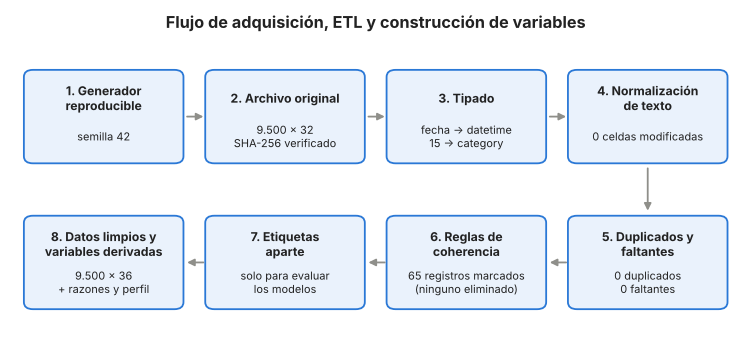

**Flujo de adquisición, ETL y construcción de variables.** El proceso parte de un generador con semilla fija y de un archivo original de 9.500 filas y 32 columnas cuya huella SHA-256 se verifica antes de continuar. Los pasos 3 a 6 ajustan tipos, texto, duplicados, faltantes y reglas de coherencia sin eliminar registros; el paso 7 aparta las etiquetas y el paso 8 entrega 9.500 registros listos para la construcción de variables.

In [8]:
# Figura 4.0 — Diagrama de flujo del proceso de adquisición, ETL y construcción de variables
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
cajas = [
    ("1. Generador\nreproducible", f"semilla {SEED}"),
    ("2. Archivo original", f"{n(antes['Filas'])} × {antes['Columnas']}\nSHA-256 verificado"),
    ("3. Tipado", f"fecha → datetime\n{len(cat_cols)+1} → category"),
    ("4. Normalización\nde texto", f"{celdas_cambiadas} celdas modificadas"),
    ("5. Duplicados y\nfaltantes", f"{dup_filas} duplicados\n{nulos} faltantes"),
    ("6. Reglas de\ncoherencia", f"{int(df['flag_alguna'].sum())} registros marcados\n(ninguno eliminado)"),
    ("7. Etiquetas\naparte", "solo para evaluar\nlos modelos"),
    ("8. Datos limpios y\nvariables derivadas", f"{n(len(datos))} × {datos.shape[1]}\n+ razones y perfil"),
]
fig, ax = plt.subplots(figsize=(7.2, 2.9)); ax.set_xlim(0, 4); ax.set_ylim(-0.05, 2.0); ax.axis("off"); ax.grid(False)
pos = [(i % 4, 1.45) for i in range(4)] + [(3 - i, 0.42) for i in range(4)]
ancho, alto = 0.84, 0.62
for (x, y), (t, d) in zip(pos, cajas):
    ax.add_patch(FancyBboxPatch((x + 0.08, y - alto / 2), ancho, alto, boxstyle="round,pad=0.02,rounding_size=0.05", fc="#eaf2fc", ec=AZUL, lw=1))
    ax.text(x + 0.08 + ancho / 2, y + 0.13, t, ha="center", va="center", fontsize=6.8, fontweight="bold", color=TINTA)
    ax.text(x + 0.08 + ancho / 2, y - 0.14, d, ha="center", va="center", fontsize=6.1, color=TINTA)
def flecha(p, q):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=8, color=GRIS, lw=1))
for i in range(3): flecha((pos[i][0] + 0.08 + ancho + 0.02, 1.45), (pos[i + 1][0] + 0.07, 1.45))
flecha((3 + 0.08 + ancho / 2, 1.45 - alto / 2 - 0.03), (3 + 0.08 + ancho / 2, 0.42 + alto / 2 + 0.03))
for i in range(4, 7): flecha((pos[i][0] + 0.07, 0.42), (pos[i + 1][0] + 0.08 + ancho + 0.02, 0.42))
ax.set_title("Flujo de adquisición, ETL y construcción de variables", fontsize=9, fontweight="bold")
guardar_fig(fig, "fig_4_0_flujo_etl")
interpretar("fig_4_0", "Flujo de adquisición, ETL y construcción de variables", [
    f"El proceso parte de un generador con semilla fija y de un archivo original de {n(antes['Filas'])} filas y {antes['Columnas']} columnas cuya huella SHA-256 se verifica antes de continuar.",
    f"Los pasos 3 a 6 ajustan tipos, texto, duplicados, faltantes y reglas de coherencia sin eliminar registros; el paso 7 aparta las etiquetas y el paso 8 entrega {n(len(datos))} registros listos para la construcción de variables.",
])

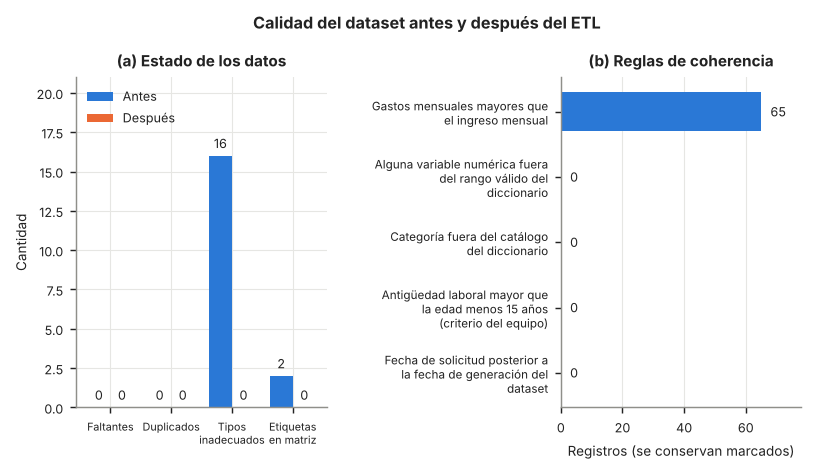

**Calidad del dataset antes y después del ETL.** El conjunto de 9.500 solicitudes no tenía valores faltantes ni duplicados, por lo que el ETL no eliminó ni imputó ningún registro. Los cambios fueron de forma: 16 columnas de texto recibieron un tipo adecuado y las 2 columnas de etiqueta salieron de la matriz de entrada. La regla de coherencia más incumplida fue «gastos mensuales mayores que el ingreso mensual» con 65 registros (0,68 %); se conservan marcados porque pueden reflejar comportamiento que interesa detectar.

In [9]:
# Figura 4.1 — Calidad antes y después del ETL
fig, ax = plt.subplots(1, 2, figsize=(7.2, 3.3), gridspec_kw={"width_ratios": [1.15, 1.1], "wspace": 0.95})
# (a) estado de los datos antes y después
ind = ["Faltantes", "Duplicados", "Tipos\ninadecuados", "Etiquetas\nen matriz"]
v_antes = [nulos, dup_filas, n_texto_inadecuado_antes, 2]; v_desp = [0, 0, 0, 0]
x = np.arange(len(ind)); w = 0.38
b1 = ax[0].bar(x - w/2, v_antes, w, color=AZUL, label="Antes"); b2 = ax[0].bar(x + w/2, v_desp, w, color=NARANJA, label="Después")
for r, v in list(zip(b1, v_antes)) + list(zip(b2, v_desp)):
    ax[0].text(r.get_x() + r.get_width()/2, v + 0.3, str(v), ha="center", va="bottom", fontsize=7)
ax[0].set_xticks(x); ax[0].set_xticklabels(ind, fontsize=6); ax[0].set_ylabel("Cantidad"); ax[0].set_ylim(0, max(v_antes) * 1.25 + 1)
ax[0].set_title("(a) Estado de los datos"); ax[0].legend(loc="upper left")
# (b) registros que incumplen cada regla de coherencia
rt = tabla_reglas.copy(); rt["etq"] = ["\n".join(textwrap.wrap(t, 30)) for t in rt["Regla de calidad"]]
ax[1].barh(rt["etq"][::-1], rt["Registros que la incumplen"][::-1], color=AZUL, height=0.6)
for i, v in enumerate(rt["Registros que la incumplen"][::-1]):
    ax[1].text(v + 3, i, n(v), va="center", fontsize=7)
ax[1].set_xlabel("Registros (se conservan marcados)"); ax[1].set_title("(b) Reglas de coherencia"); ax[1].tick_params(axis="y", labelsize=6.5)
ax[1].set_xlim(0, max(rt["Registros que la incumplen"].max() * 1.2, 10)); ax[1].grid(axis="y", visible=False)
fig.suptitle("Calidad del dataset antes y después del ETL", fontweight="bold", y=1.03, fontsize=9)
guardar_fig(fig, "fig_4_1_calidad_etl")
mayor = tabla_reglas.sort_values("Registros que la incumplen", ascending=False).iloc[0]
interpretar("fig_4_1", "Calidad del dataset antes y después del ETL", [
    f"El conjunto de {n(len(raw))} solicitudes no tenía valores faltantes ni duplicados, por lo que el ETL no eliminó ni imputó ningún registro.",
    f"Los cambios fueron de forma: {n_texto_inadecuado_antes} columnas de texto recibieron un tipo adecuado y las 2 columnas de etiqueta salieron de la matriz de entrada.",
    f"La regla de coherencia más incumplida fue «{mayor['Regla de calidad'].lower()}» con {n(mayor['Registros que la incumplen'])} registros ({n(mayor['% del total'], 2)} %); se conservan marcados porque pueden reflejar comportamiento que interesa detectar.",
])

## 5. Análisis exploratorio univariado

Se parte de los datos limpios (`datos`, sin etiquetas). Las distribuciones se describen con medidas de tendencia central y de dispersión, asimetría y curtosis.

In [10]:
NUM = ["edad", "ingreso_mensual", "gastos_mensuales", "estrato_vivienda", "antiguedad_laboral", "score_crediticio",
       "numero_creditos_vigentes", "nivel_endeudamiento", "historial_mora_dias", "monto_solicitado",
       "plazo_solicitado_meses", "tiempo_respuesta_dias", "creditos_aprobados_funcionario"]
resumen = datos[NUM].describe(percentiles=[.25, .5, .75]).T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
resumen["asimetria"] = datos[NUM].skew(); resumen["curtosis"] = datos[NUM].kurt()
resumen.insert(0, "variable", resumen.index); resumen = resumen.reset_index(drop=True)
resumen.columns = ["Variable", "n", "Media", "Desv. estándar", "Mín.", "P25", "Mediana", "P75", "Máx.", "Asimetría", "Curtosis"]
guardar_tabla(resumen.round(3), "tabla_resumen_numerico")
RESULTADOS["resumen_numerico"] = resumen.set_index("Variable")[["Media", "Mediana", "Asimetría"]].round(3).to_dict("index")
display(resumen.round(2).style.hide(axis="index").format({c: "{:,.2f}" for c in resumen.columns[1:]}))

Variable,n,Media,Desv. estándar,Mín.,P25,Mediana,P75,Máx.,Asimetría,Curtosis
edad,"9,500.00",37.01,9.78,18.00,30.00,37.00,43.00,70.00,0.16,-0.27
ingreso_mensual,"9,500.00","3,404,782.30","1,985,682.66","1,000,000.00","2,038,348.25","2,915,352.00","4,228,689.25","20,000,000.00",1.88,6.20
gastos_mensuales,"9,500.00","2,293,865.43","1,422,840.16","500,000.00","1,307,534.50","1,939,910.00","2,886,321.25","13,457,964.00",1.84,5.44
estrato_vivienda,"9,500.00",3.16,1.23,1.00,2.00,3.00,4.00,6.00,0.43,-0.27
antiguedad_laboral,"9,500.00",9.26,7.26,0.00,3.00,8.00,14.00,30.00,0.74,-0.29
score_crediticio,"9,500.00",650.34,119.71,244.00,571.00,649.00,731.00,"1,000.00",0.04,0.01
numero_creditos_vigentes,"9,500.00",2.19,1.48,0.00,1.00,2.00,3.00,9.00,0.70,0.57
nivel_endeudamiento,"9,500.00",0.85,0.41,0.10,0.50,0.86,1.21,1.50,-0.08,-1.16
historial_mora_dias,"9,500.00",29.93,38.53,0.00,3.00,13.00,44.00,180.00,1.84,3.30
monto_solicitado,"9,500.00","27,516,342.45","27,717,398.87","534,581.00","8,543,425.25","16,187,447.00","35,026,309.00","100,000,000.00",1.53,1.26


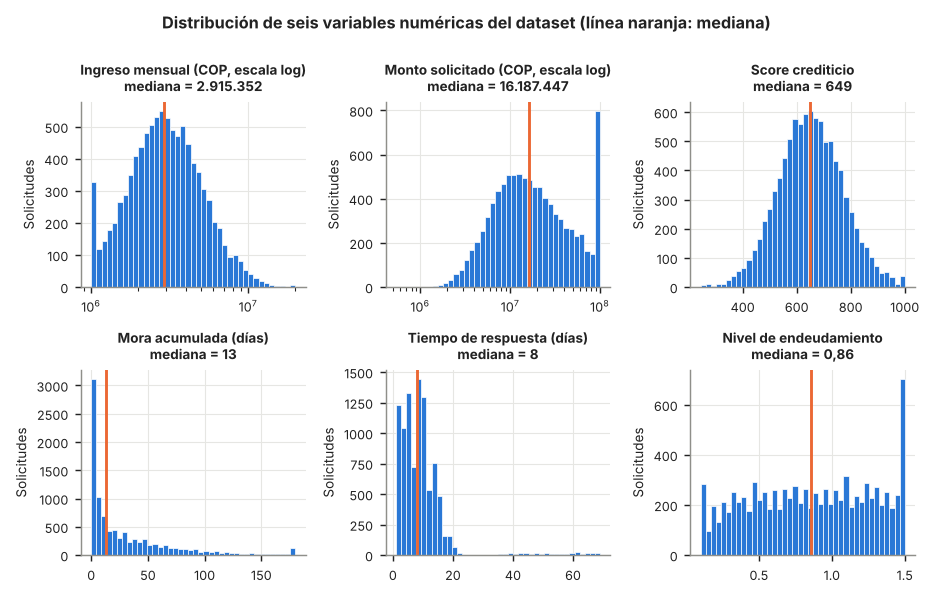

**Distribución de seis variables numéricas del dataset.** El ingreso y el monto solicitado están fuertemente sesgados a la derecha (asimetría de 1,88 y 1,53); por eso se muestran en escala logarítmica y la mediana (2.915.352 y 16.187.447 COP) resulta más representativa que la media. El tiempo de respuesta tiene mediana de 8 días y una cola larga que llega a 69 días. La mora acumulada es muy asimétrica (asimetría 1,84): la mediana es de 13 días y solo el 6,6 % de los solicitantes supera los 100.

In [11]:
# Figura 5.1 — Distribución de variables numéricas clave
claves = [("ingreso_mensual", "Ingreso mensual (COP, escala log)", True), ("monto_solicitado", "Monto solicitado (COP, escala log)", True),
          ("score_crediticio", "Score crediticio", False), ("historial_mora_dias", "Mora acumulada (días)", False),
          ("tiempo_respuesta_dias", "Tiempo de respuesta (días)", False), ("nivel_endeudamiento", "Nivel de endeudamiento", False)]
fig, axs = plt.subplots(2, 3, figsize=(7.2, 4.5))
for a, (c, t, lg) in zip(axs.ravel(), claves):
    s = datos[c]
    bins = np.geomspace(s.min(), s.max(), 40) if lg else 40
    a.hist(s, bins=bins, color=AZUL, edgecolor="white", linewidth=0.4)
    if lg: a.set_xscale("log")
    a.axvline(s.median(), color=NARANJA, lw=1.6)
    a.set_title(t + f"\nmediana = {n(s.median(), 2 if s.max() < 10 else 0)}", fontsize=7.5)
    a.set_ylabel("Solicitudes"); a.tick_params(labelsize=7)
fig.suptitle("Distribución de seis variables numéricas del dataset (línea naranja: mediana)", fontweight="bold", y=1.0, fontsize=9)
fig.tight_layout(); guardar_fig(fig, "fig_5_1_distribuciones_numericas")
sk = datos[["ingreso_mensual", "monto_solicitado", "tiempo_respuesta_dias", "historial_mora_dias"]].skew()
interpretar("fig_5_1", "Distribución de seis variables numéricas del dataset", [
    f"El ingreso y el monto solicitado están fuertemente sesgados a la derecha (asimetría de {n(sk['ingreso_mensual'], 2)} y {n(sk['monto_solicitado'], 2)}); por eso se muestran en escala logarítmica y la mediana ({n(datos['ingreso_mensual'].median())} y {n(datos['monto_solicitado'].median())} COP) resulta más representativa que la media.",
    f"El tiempo de respuesta tiene mediana de {n(datos['tiempo_respuesta_dias'].median())} días y una cola larga que llega a {n(datos['tiempo_respuesta_dias'].max())} días.",
    f"La mora acumulada es muy asimétrica (asimetría {n(sk['historial_mora_dias'], 2)}): la mediana es de {n(datos['historial_mora_dias'].median())} días y solo el {pct((datos['historial_mora_dias'] > 100).mean())} de los solicitantes supera los 100.",
])

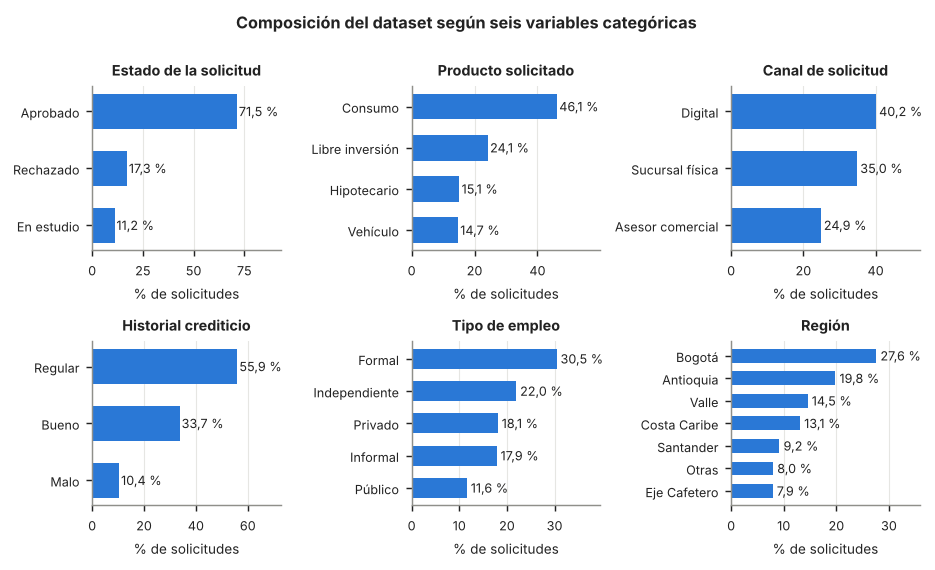

**Composición del dataset según seis variables categóricas.** El 71,5 % de las solicitudes fue aprobado, el 17,3 % rechazado y el 11,2 % sigue en estudio, de modo que la aprobación es la decisión habitual. Bogotá concentra el 27,6 % de las solicitudes y el crédito de consumo es el producto más frecuente (46,1 %). La variable «tipo de empleo» mezcla categorías que se solapan (Formal, Privado, Público, Informal e Independiente); se conserva como se generó y se documenta como limitación del diccionario.

In [12]:
# Figura 5.2 — Distribución de variables categóricas principales
cats = [("estado_aprobacion", "Estado de la solicitud"), ("tipo_producto_financiero", "Producto solicitado"), ("canal_solicitud", "Canal de solicitud"),
        ("historial_crediticio", "Historial crediticio"), ("tipo_empleo", "Tipo de empleo"), ("region", "Región")]
fig, axs = plt.subplots(2, 3, figsize=(7.2, 4.3))
for a, (c, t) in zip(axs.ravel(), cats):
    vc = datos[c].astype(str).value_counts(normalize=True).sort_values()
    a.barh(vc.index, 100 * vc.values, color=AZUL, height=0.62)
    for i, v in enumerate(vc.values): a.text(100 * v + 0.8, i, f"{n(100*v, 1)} %", va="center", fontsize=7)
    a.set_title(t, fontsize=8); a.set_xlim(0, 100 * vc.max() * 1.3); a.set_xlabel("% de solicitudes"); a.grid(axis="y", visible=False); a.tick_params(labelsize=7)
fig.suptitle("Composición del dataset según seis variables categóricas", fontweight="bold", y=1.0, fontsize=9)
fig.tight_layout(); guardar_fig(fig, "fig_5_2_distribuciones_categoricas")
ap = datos["estado_aprobacion"].value_counts(normalize=True)
interpretar("fig_5_2", "Composición del dataset según seis variables categóricas", [
    f"El {pct(ap['Aprobado'])} de las solicitudes fue aprobado, el {pct(ap['Rechazado'])} rechazado y el {pct(ap['En estudio'])} sigue en estudio, de modo que la aprobación es la decisión habitual.",
    f"Bogotá concentra el {pct(datos['region'].value_counts(normalize=True)['Bogotá'])} de las solicitudes y el crédito de consumo es el producto más frecuente ({pct(datos['tipo_producto_financiero'].value_counts(normalize=True)['Consumo'])}).",
    f"La variable «tipo de empleo» mezcla categorías que se solapan (Formal, Privado, Público, Informal e Independiente); se conserva como se generó y se documenta como limitación del diccionario.",
])

## 6. Análisis exploratorio multivariado

Esta sección responde cinco preguntas: cuántas solicitudes son anómalas; qué variables numéricas se mueven juntas (correlación de Pearson y de Spearman); qué variables repiten la misma información (VIF); si las series mensuales suben, bajan o se mantienen estables (tendencia y estacionariedad); y qué tan desbalanceadas están las clases.

> Las etiquetas se usan **solo para describir** el dataset de referencia. No se emplean para seleccionar variables, ajustar umbrales ni entrenar.

,Clase,Registros,% del total
0,Ninguna,8743,92.03
1,Monto desproporcionado vs. ingreso,249,2.62
2,Funcionario con aprobación atípica,254,2.67
3,Tiempo de respuesta excesivo,254,2.67
4,Total anómalos,757,7.97


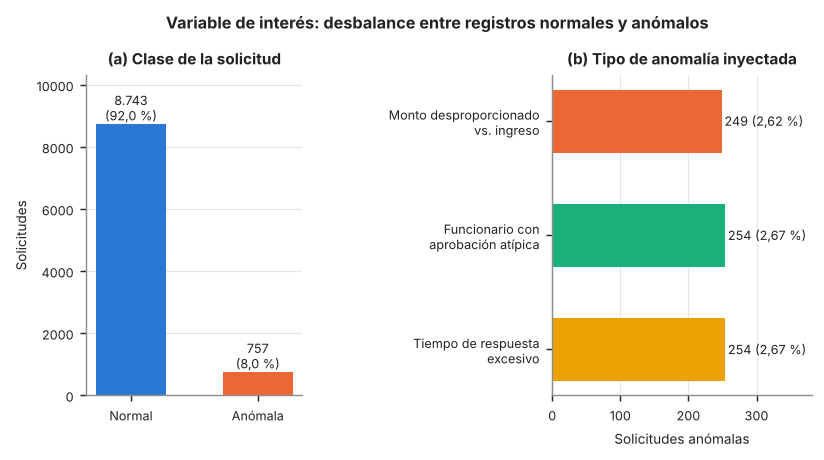

**Variable de interés: desbalance entre registros normales y anómalos.** El 7,97 % de las solicitudes (757 de 9.500) es anómalo, es decir, hay 11,5 registros normales por cada anómalo; esto se ubica dentro del rango de 5 a 10 % definido en el diseño. Los tres tipos de anomalía tienen tamaños casi iguales (249 a 254 registros), de modo que ningún tipo domina la evaluación. Un modelo que marcara todo como normal tendría una exactitud de 92,0 % sin detectar nada; por eso la evaluación usa precision, recall y F1 de la clase anómala, y un modelo que marcara todo como anómalo obtendría un F1 de apenas 0,15, valor que sirve de piso de referencia.

In [13]:
# Unión descriptiva de etiquetas (solo para el análisis exploratorio)
desc = datos.merge(etiquetas, on="id_solicitante", how="left", validate="one_to_one")
TIPOS = ["Ninguna", "Monto desproporcionado vs. ingreso", "Funcionario con aprobación atípica", "Tiempo de respuesta excesivo"]
COL_TIPO = {TIPOS[0]: AZUL, TIPOS[1]: NARANJA, TIPOS[2]: AGUA, TIPOS[3]: AMARILLO}

# ---------- 6.1 Variable de interés y desbalance de clases ----------
vc = desc["tipo_anomalia"].value_counts().reindex(TIPOS)
n_an = int(desc["es_anomalia"].sum()); n_no = int(len(desc) - n_an); prev = n_an / len(desc)
razon_desb = n_no / n_an
por_func = desc.groupby("id_funcionario_evaluador")["es_anomalia"].agg(["size", "sum", "mean"])
func_100 = por_func[por_func["mean"] == 1.0]
# línea de referencia sin información: marcar todo como anómalo
f1_todo_anomalo = 2 * prev / (1 + prev)
tabla_clases = pd.DataFrame({"Clase": TIPOS, "Registros": vc.values, "% del total": (100 * vc.values / len(desc)).round(2)})
tabla_clases.loc[len(tabla_clases)] = ["Total anómalos", n_an, round(100 * prev, 2)]
guardar_tabla(tabla_clases, "tabla_clases_objetivo")
RESULTADOS["clases"] = {"anomalos": n_an, "normales": n_no, "prevalencia": prev, "razon_normal_anomalo": razon_desb,
    "por_tipo": {k: int(v) for k, v in vc.items()}, "funcionarios_100pct_anomalos": int(len(func_100)),
    "f1_si_todo_se_marca_anomalo": f1_todo_anomalo, "exactitud_si_todo_se_marca_normal": 1 - prev}
display(tabla_clases)

fig, ax = plt.subplots(1, 2, figsize=(7.2, 3.2), gridspec_kw={"width_ratios": [1, 1.2], "wspace": 1.05})
ax[0].bar(["Normal", "Anómala"], [n_no, n_an], color=[AZUL, NARANJA], width=0.55)
for i, v in enumerate([n_no, n_an]): ax[0].text(i, v + 120, f"{n(v)}\n({pct(v/len(desc))})", ha="center", fontsize=7)
ax[0].set_ylim(0, n_no * 1.18); ax[0].set_ylabel("Solicitudes"); ax[0].set_title("(a) Clase de la solicitud"); ax[0].grid(axis="x", visible=False)
t3 = TIPOS[1:]
ax[1].barh(["\n".join(textwrap.wrap(t, 24)) for t in t3][::-1], vc[t3].values[::-1], color=[COL_TIPO[t] for t in t3][::-1], height=0.55)
for i, v in enumerate(vc[t3].values[::-1]): ax[1].text(v + 4, i, f"{n(v)} ({pct(v/len(desc), 2)})", va="center", fontsize=7)
ax[1].set_xlim(0, vc[t3].max() * 1.5); ax[1].set_xlabel("Solicitudes anómalas"); ax[1].set_title("(b) Tipo de anomalía inyectada"); ax[1].grid(axis="y", visible=False)
fig.suptitle("Variable de interés: desbalance entre registros normales y anómalos", fontweight="bold", y=1.03, fontsize=9)
guardar_fig(fig, "fig_6_1_variable_objetivo")
interpretar("fig_6_1", "Variable de interés: desbalance entre registros normales y anómalos", [
    f"El {pct(prev, 2)} de las solicitudes ({n(n_an)} de {n(len(desc))}) es anómalo, es decir, hay {n(razon_desb, 1)} registros normales por cada anómalo; esto se ubica dentro del rango de 5 a 10 % definido en el diseño.",
    f"Los tres tipos de anomalía tienen tamaños casi iguales ({n(vc[t3].min())} a {n(vc[t3].max())} registros), de modo que ningún tipo domina la evaluación.",
    f"Un modelo que marcara todo como normal tendría una exactitud de {pct(1-prev)} sin detectar nada; por eso la evaluación usa precision, recall y F1 de la clase anómala, y un modelo que marcara todo como anómalo obtendría un F1 de apenas {n(f1_todo_anomalo, 2)}, valor que sirve de piso de referencia.",
])

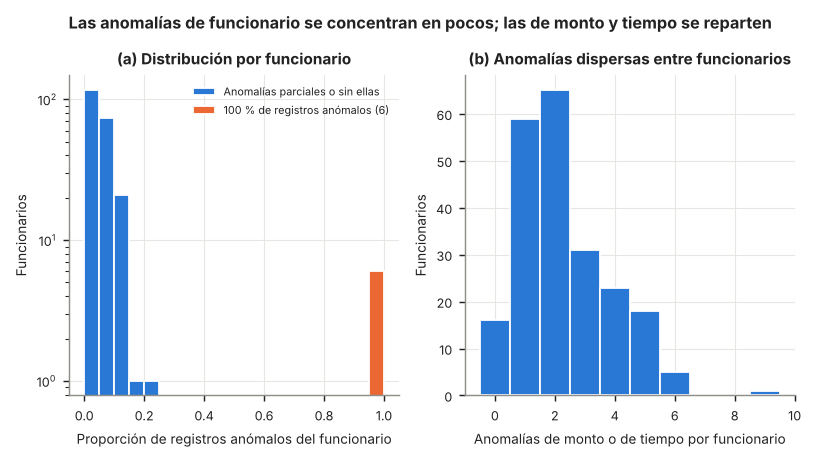

**Anomalías por funcionario.** Seis de los 220 funcionarios tienen el 100 % de sus solicitudes marcadas como anómalas, y ellos reúnen las 254 anomalías de tipo «funcionario con aprobación atípica». Las anomalías de monto y de tiempo, en cambio, se reparten entre los funcionarios (mediana de 2 por funcionario y máximo de 9). Esta diferencia justifica el diseño en dos niveles de análisis: la solicitud para las anomalías puntuales y el funcionario para el patrón sostenido de aprobación.

In [14]:
# Figura 6.2 — Anomalías por funcionario
fig, ax = plt.subplots(1, 2, figsize=(7.2, 3.2))
bins = np.linspace(0, 1, 21)
ax[0].hist(por_func.loc[por_func["mean"] < 1, "mean"], bins=bins, color=AZUL, edgecolor="white", label="Anomalías parciales o sin ellas")
ax[0].hist(func_100["mean"], bins=bins, color=NARANJA, edgecolor="white", label=f"100 % de registros anómalos ({len(func_100)})")
ax[0].set_xlabel("Proporción de registros anómalos del funcionario"); ax[0].set_ylabel("Funcionarios"); ax[0].set_yscale("log")
ax[0].legend(fontsize=6, loc="upper right"); ax[0].set_title("(a) Distribución por funcionario")
sin_func = desc.loc[desc["tipo_anomalia"] != "Funcionario con aprobación atípica"].groupby("id_funcionario_evaluador")["es_anomalia"].sum()
ax[1].hist(sin_func, bins=range(0, int(sin_func.max()) + 2), color=AZUL, edgecolor="white", align="left")
ax[1].set_xlabel("Anomalías de monto o de tiempo por funcionario"); ax[1].set_ylabel("Funcionarios"); ax[1].set_title("(b) Anomalías dispersas entre funcionarios")
fig.suptitle("Las anomalías de funcionario se concentran en pocos; las de monto y tiempo se reparten", fontweight="bold", y=1.03, fontsize=9)
guardar_fig(fig, "fig_6_2_anomalias_por_funcionario")
interpretar("fig_6_2", "Anomalías por funcionario", [
    f"Seis de los {n(len(por_func))} funcionarios tienen el 100 % de sus solicitudes marcadas como anómalas, y ellos reúnen las {n(int((desc['tipo_anomalia']=='Funcionario con aprobación atípica').sum()))} anomalías de tipo «funcionario con aprobación atípica».",
    f"Las anomalías de monto y de tiempo, en cambio, se reparten entre los funcionarios (mediana de {n(sin_func.median())} por funcionario y máximo de {n(sin_func.max())}).",
    "Esta diferencia justifica el diseño en dos niveles de análisis: la solicitud para las anomalías puntuales y el funcionario para el patrón sostenido de aprobación.",
])

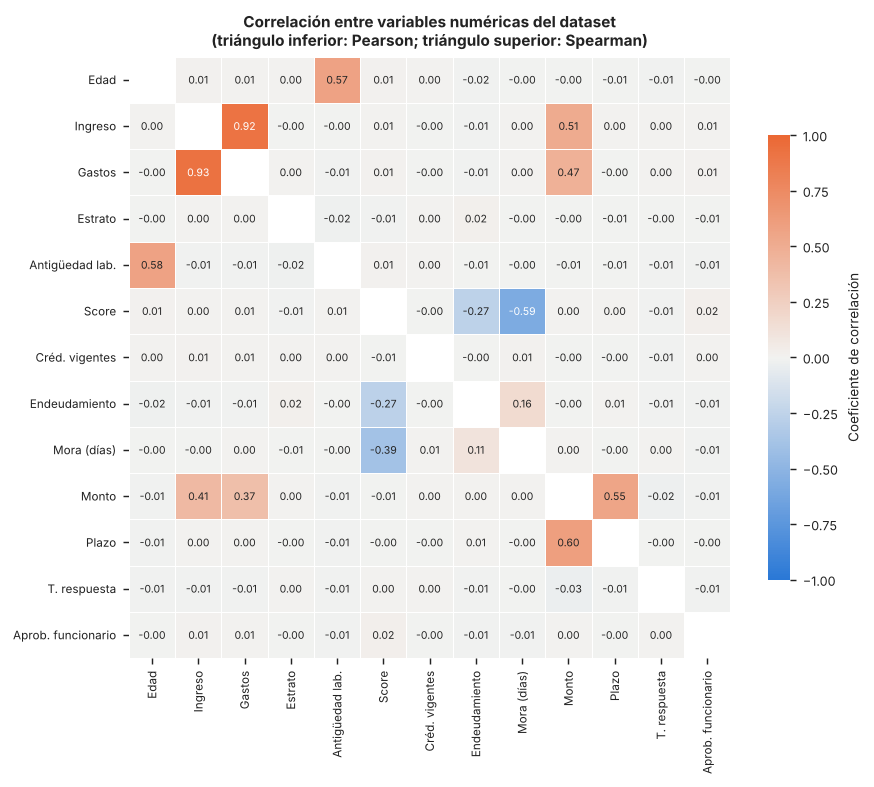

**Correlación entre variables numéricas del dataset.** Con Pearson, los pares con |r| ≥ 0,3 son: Ingreso–Gastos (r = 0,93); Monto–Plazo (r = 0,60); Edad–Antigüedad lab. (r = 0,58); Ingreso–Monto (r = 0,41). Ingreso–Gastos están casi duplicadas (r = 0,93), lo que anticipa un VIF elevado en ellas. Spearman, que mide relaciones monótonas y resiste a los valores extremos, ordena los pares de forma parecida; la mayor diferencia entre ambos coeficientes aparece en Score–Mora (días) (-0,39 frente a -0,59), señal de una relación monótona pero no lineal. Fuera de los pares citados las correlaciones son débiles, de modo que el resto de las variables aporta información distinta.

,Variable A,Variable B,Pearson,Spearman
0,Edad,Edad,1.0,1.0
28,Gastos,Gastos,1.0,1.0
14,Ingreso,Ingreso,1.0,1.0
154,T. respuesta,T. respuesta,1.0,1.0
98,Endeudamiento,Endeudamiento,1.0,1.0
84,Créd. vigentes,Créd. vigentes,1.0,1.0
70,Score,Score,1.0,1.0
56,Antigüedad lab.,Antigüedad lab.,1.0,1.0
42,Estrato,Estrato,1.0,1.0
112,Mora (días),Mora (días),1.0,1.0


In [15]:
# ---------- 6.2 Correlaciones de Pearson y Spearman (variables numéricas) ----------
pear = datos[NUM].corr(method="pearson"); spear = datos[NUM].corr(method="spearman")
etq = {"edad": "Edad", "ingreso_mensual": "Ingreso", "gastos_mensuales": "Gastos", "estrato_vivienda": "Estrato", "antiguedad_laboral": "Antigüedad lab.",
       "score_crediticio": "Score", "numero_creditos_vigentes": "Créd. vigentes", "nivel_endeudamiento": "Endeudamiento", "historial_mora_dias": "Mora (días)",
       "monto_solicitado": "Monto", "plazo_solicitado_meses": "Plazo", "tiempo_respuesta_dias": "T. respuesta", "creditos_aprobados_funcionario": "Aprob. funcionario"}
ordenadas = [etq[c] for c in NUM]
inf = np.tril(np.ones(pear.shape, dtype=bool), -1); sup = np.triu(np.ones(pear.shape, dtype=bool), 1)
comb = pd.DataFrame(np.where(inf, pear.values, np.where(sup, spear.values, np.nan)), index=ordenadas, columns=ordenadas)
fig, ax = plt.subplots(figsize=(6.9, 6.0))
sns.heatmap(comb, ax=ax, cmap=CMAP_DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 5.8},
            mask=np.eye(len(NUM), dtype=bool), cbar_kws={"shrink": 0.7, "label": "Coeficiente de correlación"}, linewidths=0.4, linecolor="white", square=True)
ax.tick_params(labelsize=6.5); ax.grid(False)
ax.set_title("Correlación entre variables numéricas del dataset\n(triángulo inferior: Pearson; triángulo superior: Spearman)", fontsize=8.5)
fig.tight_layout(); guardar_fig(fig, "fig_6_3_correlaciones")

def pares_fuertes(m, umbral=0.3):
    t = m.where(np.triu(np.ones(m.shape), 1).astype(bool)).stack()
    t = t[t.abs() >= umbral].sort_values(key=lambda s: -s.abs())
    return [(etq[a], etq[b], v) for (a, b), v in t.items()]
pf_p, pf_s = pares_fuertes(pear), pares_fuertes(spear)
dif = (pear - spear).abs().where(np.triu(np.ones(pear.shape), 1).astype(bool)).stack().sort_values(ascending=False)
(a1, b1), d1 = dif.index[0], dif.iloc[0]
tc = pd.DataFrame([(etq[a], etq[b], pear.loc[a, b], spear.loc[a, b]) for (a, b) in
                   pear.where(np.triu(np.ones(pear.shape), 1).astype(bool)).stack().index],
                  columns=["Variable A", "Variable B", "Pearson", "Spearman"])
tc["|Pearson|"] = tc["Pearson"].abs(); tc = tc.sort_values("|Pearson|", ascending=False).drop(columns="|Pearson|")
guardar_tabla(tc.round(3), "tabla_correlaciones_pares")
RESULTADOS["correlaciones"] = {"pares_pearson_ge_0_3": [(a, b, round(v, 3)) for a, b, v in pf_p], "pares_spearman_ge_0_3": [(a, b, round(v, 3)) for a, b, v in pf_s],
                               "mayor_diferencia_pearson_spearman": [etq[a1], etq[b1], round(float(d1), 3)]}
frase_pf = "; ".join(f"{a}–{b} (r = {n(v, 2)})" for a, b, v in pf_p[:4]) if pf_p else "ningún par supera 0,3"
fuertes = [(a_, b_, v) for a_, b_, v in pf_p if abs(v) >= 0.8]
frase_red = (f"{' y '.join(f'{a_}–{b_}' for a_, b_, v in fuertes)} {'están' if len(fuertes) > 1 else 'están'} casi duplicadas (r = {n(fuertes[0][2], 2)}), lo que anticipa un VIF elevado en ellas."
             if fuertes else "Ningún par llega a |r| = 0,8, así que no hay variables casi duplicadas.")
interpretar("fig_6_3", "Correlación entre variables numéricas del dataset", [
    f"Con Pearson, los pares con |r| ≥ 0,3 son: {frase_pf}. {frase_red[0].upper() + frase_red[1:]}",
    f"Spearman, que mide relaciones monótonas y resiste a los valores extremos, ordena los pares de forma parecida; la mayor diferencia entre ambos coeficientes aparece en {etq[a1]}–{etq[b1]} ({n(pear.loc[a1,b1], 2)} frente a {n(spear.loc[a1,b1], 2)}), señal de una relación monótona pero no lineal.",
    "Fuera de los pares citados las correlaciones son débiles, de modo que el resto de las variables aporta información distinta.",
])
display(tc.head(10).round(3))

,Variable,VIF,Lectura
1,ingreso_mensual,7.57,Moderada (5 a 10)
2,gastos_mensuales,7.21,Moderada (5 a 10)
9,monto_solicitado,2.09,Baja (< 5)
10,plazo_solicitado_meses,1.74,Baja (< 5)
0,edad,1.50,Baja (< 5)
4,antiguedad_laboral,1.50,Baja (< 5)
5,score_crediticio,1.26,Baja (< 5)
8,historial_mora_dias,1.18,Baja (< 5)
7,nivel_endeudamiento,1.08,Baja (< 5)
11,tiempo_respuesta_dias,1.00,Baja (< 5)


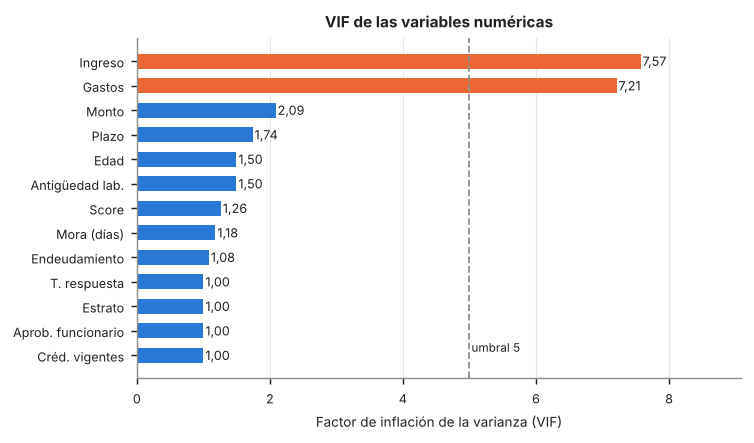

**VIF de las variables numéricas.** El VIF máximo es 7,57 (Ingreso); Ingreso y Gastos superan el umbral de 5, coherente con su correlación, y ninguna alcanza 10. La multicolinealidad es moderada y localizada, no severa. El resto de variables está por debajo de 2,1. No se elimina ninguna variable por este criterio en esta fase; la selección final queda para el Pipeline de la etapa de modelado, donde se puede reemplazar el par ingreso–gastos por la razón gasto/ingreso.

/tmp/ipykernel_232/3474261898.py:41: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp_p = kpss(s, regression="c", nlags="auto")[1]
/tmp/ipykernel_232/3474261898.py:41: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp_p = kpss(s, regression="c", nlags="auto")[1]


,Serie mensual,p ADF,p KPSS,Spearman (tiempo),p Spearman,Pendiente anual (% de la media),Conclusión
0,Solicitudes por mes,0.0,0.0782,0.2435,0.0317,0.9529,Estacionaria
1,Tiempo de respuesta medio (días),0.0,0.0409,-0.1760,0.1233,-0.7488,Resultado mixto
2,Monto solicitado medio (millones COP),0.0,0.1000,-0.0122,0.9154,0.0137,Estacionaria
3,Tasa de aprobación,0.0,0.1000,0.1202,0.2944,0.3624,Estacionaria
4,Tasa de anomalía,0.0,0.0373,-0.1952,0.0868,-3.3954,Resultado mixto


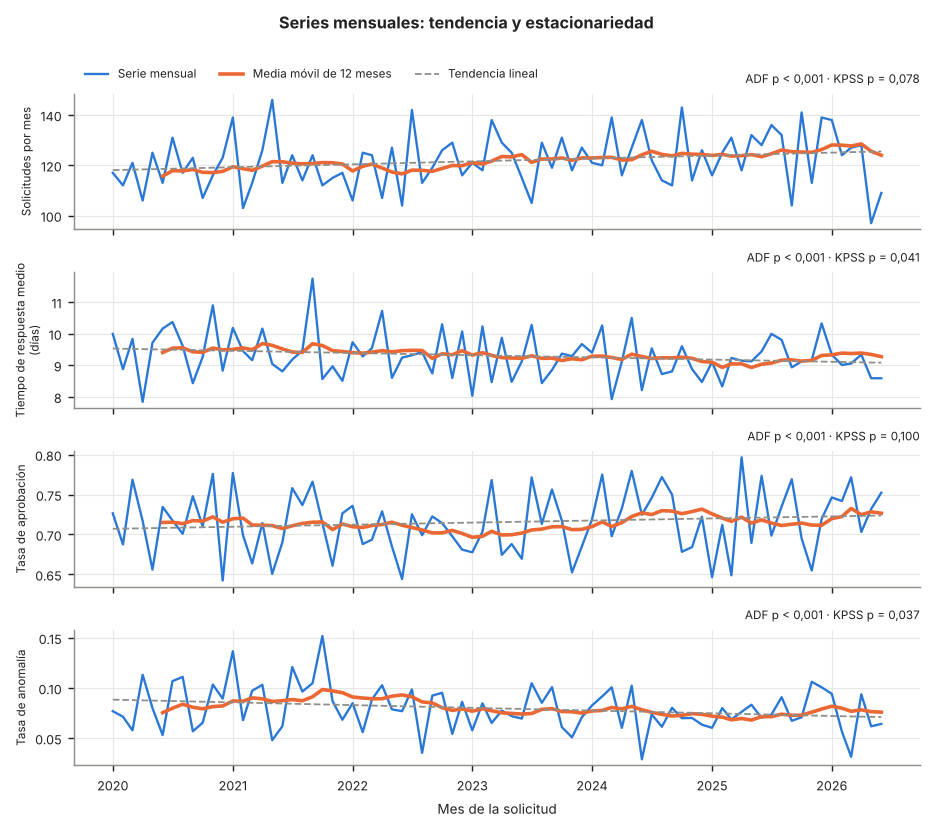

**Series mensuales: tendencia y estacionariedad.** La prueba ADF rechaza la raíz unitaria en las 5 series mensuales (78 meses), y 3 de ellas son estacionarias según ADF y KPSS en conjunto. En 2 series (tiempo de respuesta medio (días); tasa de anomalía) la prueba KPSS rechaza la estacionariedad por poco (p entre 0,037 y 0,041). Solo «solicitudes por mes» muestra una tendencia monótona débil (ρ = 0,24; p = 0,032). La media mensual de solicitudes es 121,8 y la tasa de anomalía mensual promedia 8,0 %. No hay evidencia de cambios de nivel marcados; las desviaciones son leves, de modo que bastará con incluir mes y año como variables de control en el Pipeline de la etapa de modelado.

In [16]:
# ---------- 6.3 Multicolinealidad: factor de inflación de la varianza (VIF) ----------
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
X = add_constant(datos[NUM].astype(float))
vif = pd.DataFrame({"Variable": NUM, "VIF": [variance_inflation_factor(X.values, i + 1) for i in range(len(NUM))]}).sort_values("VIF", ascending=False)
vif["Lectura"] = np.where(vif["VIF"] >= 10, "Alta (≥ 10)", np.where(vif["VIF"] >= 5, "Moderada (5 a 10)", "Baja (< 5)"))
guardar_tabla(vif.round(2), "tabla_vif")
RESULTADOS["vif"] = {r.Variable: round(float(r.VIF), 2) for r in vif.itertuples()}
display(vif.round(2))
fig, ax = plt.subplots(figsize=(6.0, 3.4))
v = vif.sort_values("VIF")
ax.barh([etq[c] for c in v["Variable"]], v["VIF"], color=[NARANJA if x >= 5 else AZUL for x in v["VIF"]], height=0.62)
for i, x in enumerate(v["VIF"]): ax.text(x + 0.03, i, n(x, 2), va="center", fontsize=7)
ax.axvline(5, color=GRIS, ls="--", lw=1); ax.text(5.03, 0.15, "umbral 5", fontsize=6.5, color=TINTA)
ax.set_xlabel("Factor de inflación de la varianza (VIF)"); ax.set_title("VIF de las variables numéricas"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(6, v["VIF"].max() * 1.2))
guardar_fig(fig, "fig_6_4_vif")
alto = vif[vif["VIF"] >= 5]; critico = vif[vif["VIF"] >= 10]
lista_alto = " y ".join(etq[c] for c in alto["Variable"])
interpretar("fig_6_4", "VIF de las variables numéricas", [
    f"El VIF máximo es {n(vif['VIF'].max(), 2)} ({etq[vif.iloc[0]['Variable']]}); " + (f"{lista_alto} superan el umbral de 5, coherente con su correlación, " if len(alto) else "ninguna variable supera el umbral de 5, ") + ("y ninguna alcanza 10." if critico.empty else f"y {', '.join(etq[c] for c in critico['Variable'])} superan 10."),
    "La multicolinealidad es " + ("moderada y localizada, no severa." if critico.empty and len(alto) else ("severa." if len(critico) else "baja.")) + " El resto de variables está por debajo de 2,1.",
    "No se elimina ninguna variable por este criterio en esta fase; la selección final queda para el Pipeline de la etapa de modelado, donde se puede reemplazar el par ingreso–gastos por la razón gasto/ingreso.",
])

# ---------- 6.4 Tendencia y estacionariedad ----------
from statsmodels.tsa.stattools import adfuller, kpss
base = desc.assign(aprobado=(desc["estado_aprobacion"] == "Aprobado").astype(int)).set_index("fecha_solicitud").sort_index()
mensual = pd.DataFrame({
    "Solicitudes por mes": base["id_solicitante"].resample("MS").size(),
    "Tiempo de respuesta medio (días)": base["tiempo_respuesta_dias"].resample("MS").mean(),
    "Monto solicitado medio (millones COP)": base["monto_solicitado"].resample("MS").mean() / 1e6,
    "Tasa de aprobación": base["aprobado"].resample("MS").mean(),
    "Tasa de anomalía": base["es_anomalia"].resample("MS").mean(),
})
filas = []
t_idx = np.arange(len(mensual))
for c in mensual.columns:
    s = mensual[c].values
    adf_p = adfuller(s, autolag="AIC")[1]
    kp_p = kpss(s, regression="c", nlags="auto")[1]
    rho, p_rho = stats.spearmanr(t_idx, s)
    lr = stats.linregress(t_idx, s)
    pend_anual_pct = 100 * lr.slope * 12 / s.mean()
    if adf_p < 0.05 and kp_p >= 0.05: concl = "Estacionaria"
    elif adf_p >= 0.05 and kp_p < 0.05: concl = "No estacionaria"
    else: concl = "Resultado mixto"
    filas.append((c, adf_p, kp_p, rho, p_rho, pend_anual_pct, concl))
est = pd.DataFrame(filas, columns=["Serie mensual", "p ADF", "p KPSS", "Spearman (tiempo)", "p Spearman", "Pendiente anual (% de la media)", "Conclusión"])
guardar_tabla(est.round(4), "tabla_estacionariedad")
RESULTADOS["estacionariedad"] = {r["Serie mensual"]: {"p_adf": round(r["p ADF"], 4), "p_kpss": round(r["p KPSS"], 4), "rho": round(r["Spearman (tiempo)"], 3),
                                 "p_rho": round(r["p Spearman"], 4), "conclusion": r["Conclusión"]} for _, r in est.iterrows()}
RESULTADOS["n_meses"] = int(len(mensual))
display(est.round(4))

fig, axs = plt.subplots(4, 1, figsize=(7.2, 6.3), sharex=True)
for a, c in zip(axs, ["Solicitudes por mes", "Tiempo de respuesta medio (días)", "Tasa de aprobación", "Tasa de anomalía"]):
    s = mensual[c]
    a.plot(s.index, s.values, color=AZUL, lw=1.3, label="Serie mensual")
    a.plot(s.index, s.rolling(12, min_periods=6).mean(), color=NARANJA, lw=2, label="Media móvil de 12 meses")
    lr = stats.linregress(t_idx, s.values); a.plot(s.index, lr.intercept + lr.slope * t_idx, color=GRIS, ls="--", lw=1, label="Tendencia lineal")
    a.set_ylabel(c.replace(" (", "\n("), fontsize=6.5)
    pa, pk = est.set_index("Serie mensual").loc[c, ["p ADF", "p KPSS"]]
    a.set_title(f"ADF p {'< 0,001' if pa < 0.001 else '= ' + n(pa, 3)} · KPSS p = {n(pk, 3)}", loc="right", fontsize=6.5, fontweight="normal")
axs[0].legend(ncol=3, fontsize=6.5, loc="lower left", bbox_to_anchor=(0, 1.02)); axs[-1].set_xlabel("Mes de la solicitud")
fig.suptitle("Series mensuales: tendencia y estacionariedad", fontweight="bold", y=1.0, fontsize=9)
fig.tight_layout(); guardar_fig(fig, "fig_6_5_series_temporales")
n_est = int((est["Conclusión"] == "Estacionaria").sum())
mixtas = est.loc[est["Conclusión"] == "Resultado mixto", "Serie mensual"].tolist()
con_tend = est.loc[est["p Spearman"] < 0.05, ["Serie mensual", "Spearman (tiempo)", "p Spearman", "Pendiente anual (% de la media)"]]
adf_todas = bool((est["p ADF"] < 0.05).all())
fr_mix = (f" En {len(mixtas)} {'series' if len(mixtas)>1 else 'serie'} ({'; '.join(m.lower() for m in mixtas)}) la prueba KPSS rechaza la estacionariedad por poco (p entre {n(est.loc[est['Serie mensual'].isin(mixtas), 'p KPSS'].min(), 3)} y {n(est.loc[est['Serie mensual'].isin(mixtas), 'p KPSS'].max(), 3)})." if mixtas else "")
fr_tend = (" Solo " + "; ".join(f"«{r['Serie mensual'].lower()}» muestra una tendencia monótona débil (ρ = {n(r['Spearman (tiempo)'], 2)}; p = {n(r['p Spearman'], 3)})" for _, r in con_tend.iterrows()) + ".") if len(con_tend) else " Ninguna serie muestra tendencia monótona significativa."
interpretar("fig_6_5", "Series mensuales: tendencia y estacionariedad", [
    f"La prueba ADF rechaza la raíz unitaria en {'las' if adf_todas else 'algunas de las'} {len(est)} series mensuales ({len(mensual)} meses), y {n_est} de ellas son estacionarias según ADF y KPSS en conjunto." + fr_mix + fr_tend,
    f"La media mensual de solicitudes es {n(mensual['Solicitudes por mes'].mean(), 1)} y la tasa de anomalía mensual promedia {pct(mensual['Tasa de anomalía'].mean())}.",
    "No hay evidencia de cambios de nivel marcados; las desviaciones son leves, de modo que bastará con incluir mes y año como variables de control en el Pipeline de la etapa de modelado."
])

## 7. Ingeniería de características

Se construyen variables en los dos niveles de análisis del apartado 7.2 del informe. El código está en `src/features.py` y **ninguna función lee las etiquetas**.

* **Nivel de solicitud:** razones financieras calculadas fila a fila (por ejemplo, monto sobre ingreso). No dependen del resto de los datos.
* **Nivel de funcionario:** indicadores agregados (tasa de aprobación, tasa de excepciones, tiempo de respuesta promedio, monto promedio) y su distancia frente al grupo de pares, medida en puntaje Z. Como el puntaje Z usa el promedio y la desviación estándar del grupo, en el objetivo 2 esa referencia se calculará solo con los datos de entrenamiento.

Se usa la **tasa** de aprobación y no la columna `creditos_aprobados_funcionario`, porque esta es un conteo que depende de cuántas solicitudes recibió cada funcionario y no permite compararlos.

In [17]:
from src.features import razones_solicitud, perfil_funcionario, desviacion_pares, INDICADORES_PARES, COLUMNAS_ETIQUETA

# ---------- Nivel de solicitud ----------
razones = razones_solicitud(datos)
matriz = pd.concat([datos, razones.drop(columns=["mes", "anio"]).join(razones[["mes", "anio"]])], axis=1)
assert not set(COLUMNAS_ETIQUETA) & set(matriz.columns)
DEF_VARS = pd.DataFrame([
    ("razon_monto_ingreso", "Solicitud", "Monto solicitado / ingreso mensual", "Mide qué tan grande es el crédito frente a la capacidad de ingreso; apunta a montos desproporcionados."),
    ("razon_gasto_ingreso", "Solicitud", "Gastos mensuales / ingreso mensual", "Mide la holgura financiera del solicitante."),
    ("capacidad_residual", "Solicitud", "Ingreso − gastos (COP)", "Capacidad de pago disponible; negativa si los gastos superan el ingreso."),
    ("cuota_estimada", "Solicitud", "Monto / plazo en meses (COP, sin intereses)", "Aproxima el pago mensual exigido."),
    ("razon_cuota_ingreso", "Solicitud", "Cuota estimada / ingreso mensual", "Carga de la cuota sobre el ingreso."),
    ("razon_cuota_capacidad", "Solicitud", "Cuota estimada / capacidad residual (solo si es positiva)", "Carga de la cuota sobre la capacidad real; vacía si no hay capacidad."),
    ("excepcion_bin", "Solicitud", "1 si hubo excepción a políticas internas", "Codificación binaria directa, sin parámetros aprendidos."),
    ("aprobado_bin / decidido_bin", "Solicitud", "1 si Aprobado / 1 si Aprobado o Rechazado", "Insumo para las tasas por funcionario."),
    ("mes, anio", "Solicitud", "Componentes de la fecha", "Permiten controlar la estacionalidad."),
    ("tasa_aprobacion", "Funcionario", "Aprobadas / atendidas", "Frecuencia con que el funcionario aprueba."),
    ("tasa_aprobacion_decididas", "Funcionario", "Aprobadas / (aprobadas + rechazadas)", "Versión que excluye las solicitudes aún en estudio."),
    ("tasa_excepciones", "Funcionario", "Solicitudes con excepción / atendidas", "Uso de excepciones a políticas internas."),
    ("monto_promedio, monto_mediano", "Funcionario", "Promedio y mediana del monto de sus solicitudes", "Nivel de los montos que aprueba o evalúa."),
    ("razon_monto_ingreso_prom", "Funcionario", "Promedio de monto / ingreso", "Montos relativos al ingreso de sus solicitantes."),
    ("tiempo_resp_prom, tiempo_resp_p90", "Funcionario", "Media y percentil 90 del tiempo de respuesta", "Rapidez y colas de demora."),
    ("score_prom, mora_prom", "Funcionario", "Promedio de score y de mora de los solicitantes", "Perfil de riesgo de los solicitantes que atiende."),
    ("z_*", "Funcionario", "(indicador − media de pares) / desviación de pares", "Desviación frente al grupo; la referencia se ajusta solo con entrenamiento en el objetivo 2."),
], columns=["Variable", "Nivel", "Definición", "Para qué sirve"])
guardar_tabla(DEF_VARS, "tabla_variables_derivadas")
display(DEF_VARS.style.hide(axis="index").set_properties(**{"text-align": "left"}))

# ---------- Nivel de funcionario ----------
perfil = perfil_funcionario(datos, razones)
z = desviacion_pares(perfil)                       # referencia = todos los funcionarios (solo descriptivo)
perfil_z = perfil.join(z)
assert len(perfil_z) == datos["id_funcionario_evaluador"].nunique()
resumen_perfil = perfil[INDICADORES_PARES].describe().T[["mean", "std", "min", "50%", "max"]]
resumen_perfil.columns = ["Media", "Desv. estándar", "Mín.", "Mediana", "Máx."]
resumen_perfil.insert(0, "Indicador", resumen_perfil.index); resumen_perfil = resumen_perfil.reset_index(drop=True)
guardar_tabla(resumen_perfil.round(3), "tabla_perfil_funcionario_resumen")
display(resumen_perfil.round(3))

# ---------- Guardado ----------
matriz_out = matriz.copy(); matriz_out["fecha_solicitud"] = matriz_out["fecha_solicitud"].dt.strftime("%Y-%m-%d")
for c in cat_cols: matriz_out[c] = matriz_out[c].astype(str)
matriz_out.to_csv(PROC / "matriz_solicitud.csv", index=False, encoding="utf-8-sig")
perfil_z.to_csv(PROC / "perfil_funcionario.csv", encoding="utf-8-sig")
# etiqueta a nivel de funcionario (solo evaluación): 1 si alguno de sus registros es de tipo "Funcionario con aprobación atípica"
etq_func = (desc.assign(f=(desc["tipo_anomalia"] == "Funcionario con aprobación atípica").astype(int))
            .groupby("id_funcionario_evaluador")["f"].max().rename("funcionario_atipico"))
etq_func.to_csv(PROC / "etiquetas_evaluacion_funcionario.csv", encoding="utf-8-sig")
RESULTADOS["features"] = {"columnas_matriz_solicitud": int(matriz.shape[1]), "variables_derivadas_solicitud": int(razones.shape[1]),
                          "funcionarios": int(len(perfil_z)), "indicadores_perfil": int(perfil.shape[1]), "columnas_z": int(z.shape[1]),
                          "funcionarios_atipicos": int(etq_func.sum())}

Variable,Nivel,Definición,Para qué sirve
razon_monto_ingreso,Solicitud,Monto solicitado / ingreso mensual,Mide qué tan grande es el crédito frente a la capacidad de ingreso; apunta a montos desproporcionados.
razon_gasto_ingreso,Solicitud,Gastos mensuales / ingreso mensual,Mide la holgura financiera del solicitante.
capacidad_residual,Solicitud,Ingreso − gastos (COP),Capacidad de pago disponible; negativa si los gastos superan el ingreso.
cuota_estimada,Solicitud,"Monto / plazo en meses (COP, sin intereses)",Aproxima el pago mensual exigido.
razon_cuota_ingreso,Solicitud,Cuota estimada / ingreso mensual,Carga de la cuota sobre el ingreso.
razon_cuota_capacidad,Solicitud,Cuota estimada / capacidad residual (solo si es positiva),Carga de la cuota sobre la capacidad real; vacía si no hay capacidad.
excepcion_bin,Solicitud,1 si hubo excepción a políticas internas,"Codificación binaria directa, sin parámetros aprendidos."
aprobado_bin / decidido_bin,Solicitud,1 si Aprobado / 1 si Aprobado o Rechazado,Insumo para las tasas por funcionario.
"mes, anio",Solicitud,Componentes de la fecha,Permiten controlar la estacionalidad.
tasa_aprobacion,Funcionario,Aprobadas / atendidas,Frecuencia con que el funcionario aprueba.


,Indicador,Media,Desv. estándar,Mín.,Mediana,Máx.
0,tasa_aprobacion,7.160000e-01,0.082,4.860000e-01,7.080000e-01,1.000000e+00
1,tasa_excepciones,9.000000e-02,0.082,0.000000e+00,7.800000e-02,6.190000e-01
2,monto_promedio,2.750641e+07,4191147.053,1.748000e+07,2.745468e+07,4.063631e+07
3,razon_monto_ingreso_prom,8.614000e+00,1.229,5.629000e+00,8.538000e+00,1.196900e+01
4,tiempo_resp_prom,9.310000e+00,1.357,6.559000e+00,9.165000e+00,1.443200e+01


,Anomalía,Unidad,Variable,Nombre,Origen,AUC
0,Monto desproporcionado vs. ingreso,solicitud,ingreso_mensual,Ingreso mensual,Original,0.514
1,Monto desproporcionado vs. ingreso,solicitud,monto_solicitado,Monto solicitado,Original,0.948
2,Monto desproporcionado vs. ingreso,solicitud,razon_monto_ingreso,Razón monto/ingreso,Derivada,0.951
3,Monto desproporcionado vs. ingreso,solicitud,razon_cuota_ingreso,Razón cuota/ingreso,Derivada,0.959
4,Tiempo de respuesta excesivo,solicitud,tiempo_respuesta_dias,Tiempo de respuesta,Original,1.000
5,Funcionario con aprobación atípica,solicitud,aprobado_bin,Aprobada (0/1),Original,0.642
6,Funcionario con aprobación atípica,solicitud,excepcion_bin,Con excepción (0/1),Original,0.704
7,Funcionario con aprobación atípica,funcionario,tasa_aprobacion,Tasa de aprobación,Derivada,1.000
8,Funcionario con aprobación atípica,funcionario,tasa_excepciones,Tasa de excepciones,Derivada,1.000


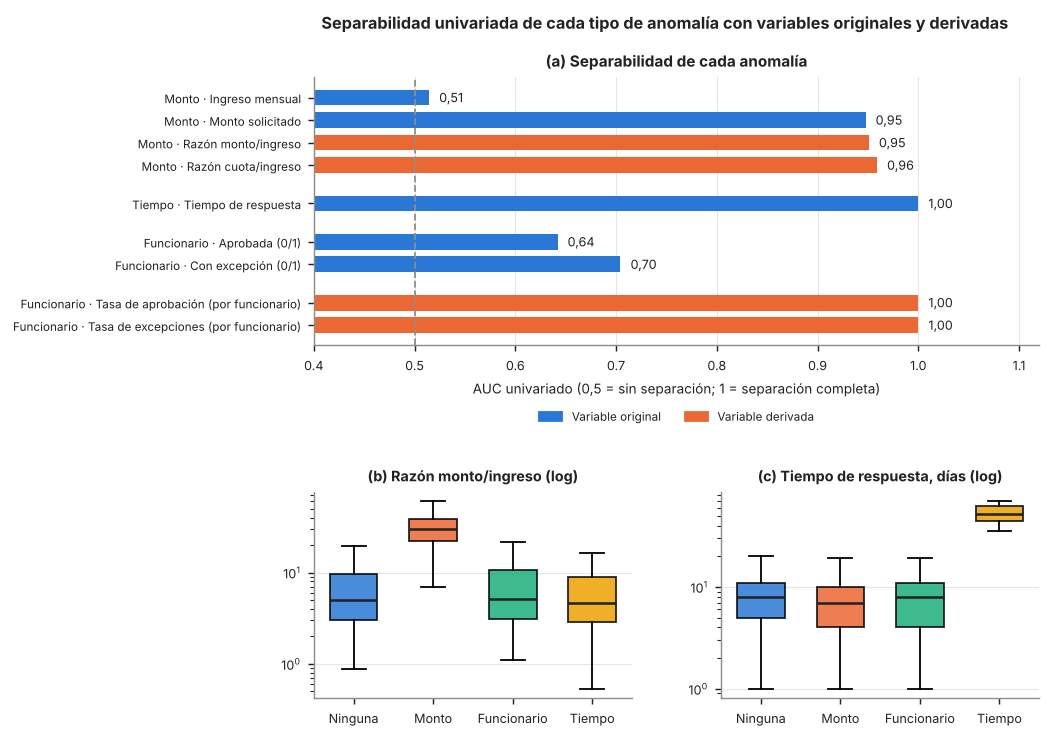

**Separabilidad univariada de cada tipo de anomalía.** Para la anomalía de monto, el ingreso solo no separa los casos (AUC 0,51), el monto sí (AUC 0,95) y las razones derivadas apenas lo mejoran (0,95 y 0,96); además, 444 solicitudes normales superan una razón monto/ingreso de 25 (el límite inferior con que se inyectó la anomalía) y 77 anomalías de monto quedan por debajo de ese valor por el tope de 100 millones de pesos, lo que impide una separación completa. Para el patrón de funcionario, la aprobación y la excepción de cada solicitud separan poco (AUC 0,64 y 0,70), pero sus tasas por funcionario lo hacen por completo (1,00 y 1,00): ahí está el aporte principal de la ingeniería de características. El tiempo de respuesta ya separa por completo su anomalía con la variable original (AUC 1,00; el mayor tiempo normal es de 26 días y el menor anómalo de 35). Esta es una descripción del dataset sintético, no el desempeño de un modelo, y no se usó para elegir variables.

In [18]:
# Figura 7.1 — Separabilidad univariada de cada tipo de anomalía (descriptiva; no se usa para seleccionar variables)
from sklearn.metrics import roc_auc_score
from matplotlib.patches import Patch
dd = pd.concat([datos.reset_index(drop=True), razones.reset_index(drop=True)], axis=1).merge(etiquetas, on="id_solicitante")
T_MONTO, T_FUNC, T_TIEMPO = "Monto desproporcionado vs. ingreso", "Funcionario con aprobación atípica", "Tiempo de respuesta excesivo"

def auc_solicitud(var, tipo):
    # AUC = probabilidad de que una solicitud anómala del tipo dado tenga un valor mayor que una normal (descriptivo, no es un modelo)
    sub = dd[dd["tipo_anomalia"].isin(["Ninguna", tipo])].dropna(subset=[var])
    return roc_auc_score((sub["tipo_anomalia"] == tipo).astype(int), sub[var])

filas_auc = [  # (anomalía, unidad, variable, nombre, origen, auc)
    (T_MONTO, "solicitud", "ingreso_mensual", "Ingreso mensual", "Original", auc_solicitud("ingreso_mensual", T_MONTO)),
    (T_MONTO, "solicitud", "monto_solicitado", "Monto solicitado", "Original", auc_solicitud("monto_solicitado", T_MONTO)),
    (T_MONTO, "solicitud", "razon_monto_ingreso", "Razón monto/ingreso", "Derivada", auc_solicitud("razon_monto_ingreso", T_MONTO)),
    (T_MONTO, "solicitud", "razon_cuota_ingreso", "Razón cuota/ingreso", "Derivada", auc_solicitud("razon_cuota_ingreso", T_MONTO)),
    (T_TIEMPO, "solicitud", "tiempo_respuesta_dias", "Tiempo de respuesta", "Original", auc_solicitud("tiempo_respuesta_dias", T_TIEMPO)),
    (T_FUNC, "solicitud", "aprobado_bin", "Aprobada (0/1)", "Original", auc_solicitud("aprobado_bin", T_FUNC)),
    (T_FUNC, "solicitud", "excepcion_bin", "Con excepción (0/1)", "Original", auc_solicitud("excepcion_bin", T_FUNC)),
    (T_FUNC, "funcionario", "tasa_aprobacion", "Tasa de aprobación", "Derivada", roc_auc_score(etq_func.loc[perfil.index], perfil["tasa_aprobacion"])),
    (T_FUNC, "funcionario", "tasa_excepciones", "Tasa de excepciones", "Derivada", roc_auc_score(etq_func.loc[perfil.index], perfil["tasa_excepciones"])),
]
tabla_auc = pd.DataFrame(filas_auc, columns=["Anomalía", "Unidad", "Variable", "Nombre", "Origen", "AUC"])
guardar_tabla(tabla_auc.round(3), "tabla_separabilidad_univariada")
RESULTADOS["auc_univariado"] = {f"{v}|{u}": round(float(a), 3) for v, u, a in zip(tabla_auc["Variable"], tabla_auc["Unidad"], tabla_auc["AUC"])}
A = {(v, u): a for v, u, a in zip(tabla_auc["Variable"], tabla_auc["Unidad"], tabla_auc["AUC"])}
display(tabla_auc.round(3))

fig = plt.figure(figsize=(7.2, 6.2)); gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 1], hspace=0.62, wspace=0.28)
axs = [fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])]
pos, y = [], 0
for g in [(T_MONTO, "solicitud"), (T_TIEMPO, "solicitud"), (T_FUNC, "solicitud"), (T_FUNC, "funcionario")]:
    for _, r in tabla_auc[(tabla_auc["Anomalía"] == g[0]) & (tabla_auc["Unidad"] == g[1])].iterrows():
        pos.append((y, r)); y += 1
    y += 0.7
for yy, r in pos:
    axs[0].barh(yy, r["AUC"], color=NARANJA if r["Origen"] == "Derivada" else AZUL, height=0.7)
    axs[0].text(r["AUC"] + 0.01, yy, n(r["AUC"], 2), va="center", fontsize=7)
axs[0].set_yticks([yy for yy, _ in pos]); axs[0].set_yticklabels([("Monto · " if r["Anomalía"] == T_MONTO else "Tiempo · " if r["Anomalía"] == T_TIEMPO else "Funcionario · ") + r["Nombre"] + (" (por funcionario)" if r["Unidad"] == "funcionario" else "") for _, r in pos], fontsize=6.5)
axs[0].invert_yaxis(); axs[0].axvline(0.5, color=GRIS, ls="--", lw=1); axs[0].set_xlim(0.4, 1.12); axs[0].grid(axis="y", visible=False)
axs[0].set_xlabel("AUC univariado (0,5 = sin separación; 1 = separación completa)"); axs[0].set_title("(a) Separabilidad de cada anomalía")
axs[0].legend(handles=[Patch(color=AZUL, label="Variable original"), Patch(color=NARANJA, label="Variable derivada")], fontsize=6.5, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
for a, (c, t) in zip(axs[1:], [("razon_monto_ingreso", "(b) Razón monto/ingreso (log)"), ("tiempo_respuesta_dias", "(c) Tiempo de respuesta, días (log)")]):
    datos_box = [dd.loc[dd["tipo_anomalia"] == k, c].dropna().values for k in TIPOS]
    bp = a.boxplot(datos_box, patch_artist=True, widths=0.6, showfliers=False, medianprops={"color": TINTA, "lw": 1.4})
    for patch, k in zip(bp["boxes"], TIPOS): patch.set_facecolor(COL_TIPO[k]); patch.set_alpha(0.85)
    a.set_yscale("log"); a.set_xticklabels(["Ninguna", "Monto", "Funcionario", "Tiempo"], fontsize=7); a.set_title(t, fontsize=8); a.grid(axis="x", visible=False)
fig.suptitle("Separabilidad univariada de cada tipo de anomalía con variables originales y derivadas", fontweight="bold", y=0.96, fontsize=9)
guardar_fig(fig, "fig_7_1_valor_variables_derivadas")
max_normal_t = int(dd.loc[dd["tipo_anomalia"] == "Ninguna", "tiempo_respuesta_dias"].max()); min_anom_t = int(dd.loc[dd["tipo_anomalia"] == T_TIEMPO, "tiempo_respuesta_dias"].min())
r_min = float(dd.loc[dd["tipo_anomalia"] == T_MONTO, "razon_monto_ingreso"].min())
n_norm_ratio = int(((dd["tipo_anomalia"] == "Ninguna") & (dd["razon_monto_ingreso"] >= 25)).sum())      # 25 = límite inferior nominal de la anomalía inyectada
n_anom_bajo = int(((dd["tipo_anomalia"] == T_MONTO) & (dd["razon_monto_ingreso"] < 25)).sum())
RESULTADOS["separabilidad"] = {"tiempo_max_normal": max_normal_t, "tiempo_min_anomalo": min_anom_t, "razon_min_anomalia_monto": round(r_min, 2), "normales_con_razon_mayor_o_igual_25": n_norm_ratio, "anomalias_monto_con_razon_menor_25": n_anom_bajo}
interpretar("fig_7_1", "Separabilidad univariada de cada tipo de anomalía", [
    f"Para la anomalía de monto, el ingreso solo no separa los casos (AUC {n(A[('ingreso_mensual','solicitud')], 2)}), el monto sí (AUC {n(A[('monto_solicitado','solicitud')], 2)}) y las razones derivadas apenas lo mejoran ({n(A[('razon_monto_ingreso','solicitud')], 2)} y {n(A[('razon_cuota_ingreso','solicitud')], 2)}); además, {n(n_norm_ratio)} solicitudes normales superan una razón monto/ingreso de 25 (el límite inferior con que se inyectó la anomalía) y {n(n_anom_bajo)} anomalías de monto quedan por debajo de ese valor por el tope de 100 millones de pesos, lo que impide una separación completa.",
    f"Para el patrón de funcionario, la aprobación y la excepción de cada solicitud separan poco (AUC {n(A[('aprobado_bin','solicitud')], 2)} y {n(A[('excepcion_bin','solicitud')], 2)}), pero sus tasas por funcionario lo hacen por completo ({n(A[('tasa_aprobacion','funcionario')], 2)} y {n(A[('tasa_excepciones','funcionario')], 2)}): ahí está el aporte principal de la ingeniería de características.",
    f"El tiempo de respuesta ya separa por completo su anomalía con la variable original (AUC {n(A[('tiempo_respuesta_dias','solicitud')], 2)}; el mayor tiempo normal es de {max_normal_t} días y el menor anómalo de {min_anom_t}). Esta es una descripción del dataset sintético, no el desempeño de un modelo, y no se usó para elegir variables.",
])

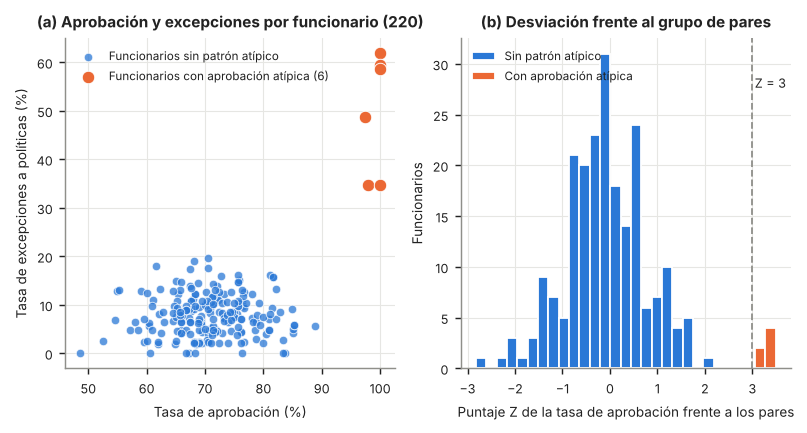

**Perfil de los funcionarios evaluadores.** Los seis funcionarios con aprobación atípica aprueban entre 97,4 % y 100,0 % de sus solicitudes y usan excepciones a políticas en 34,7 % a 61,9 % de ellas; entre los demás, la tasa de aprobación máxima es 88,9 % y la de excepciones 19,6 %. Frente al grupo de pares, 6 de esos seis funcionarios tienen un puntaje Z de aprobación de 3 o más, y ningún otro funcionario lo alcanza. Los indicadores por funcionario hacen visible un patrón que no se aprecia solicitud por solicitud, base del nivel de análisis de funcionario (H2); la separación es nítida porque las anomalías se inyectaron con valores extremos, y en datos reales se espera más solapamiento, por lo que los resultados del objetivo 2 se leerán como un escenario favorable.

In [19]:
# Figura 7.2 — Perfil por funcionario
pf = perfil_z.join(etq_func)
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.3))
for flag, color, lab in [(0, AZUL, "Funcionarios sin patrón atípico"), (1, NARANJA, "Funcionarios con aprobación atípica (6)")]:
    s = pf[pf["funcionario_atipico"] == flag]
    axs[0].scatter(100 * s["tasa_aprobacion"], 100 * s["tasa_excepciones"], s=22 if flag == 0 else 48, color=color, alpha=0.75 if flag == 0 else 1,
                   edgecolor="white", linewidth=0.5, label=lab, zorder=3 if flag else 2)
axs[0].set_xlabel("Tasa de aprobación (%)"); axs[0].set_ylabel("Tasa de excepciones a políticas (%)"); axs[0].legend(fontsize=6.5, loc="upper left")
axs[0].set_title("(a) Aprobación y excepciones por funcionario (220)")
zc = "z_tasa_aprobacion"
bins = np.linspace(pf[zc].min(), pf[zc].max(), 30)
axs[1].hist(pf.loc[pf["funcionario_atipico"] == 0, zc], bins=bins, color=AZUL, edgecolor="white", label="Sin patrón atípico")
axs[1].hist(pf.loc[pf["funcionario_atipico"] == 1, zc], bins=bins, color=NARANJA, edgecolor="white", label="Con aprobación atípica")
axs[1].axvline(3, color=GRIS, ls="--", lw=1); axs[1].text(3.05, axs[1].get_ylim()[1] * 0.85, "Z = 3", fontsize=7)
axs[1].set_xlabel("Puntaje Z de la tasa de aprobación frente a los pares"); axs[1].set_ylabel("Funcionarios"); axs[1].legend(fontsize=6.5, loc="upper left"); axs[1].set_title("(b) Desviación frente al grupo de pares")
guardar_fig(fig, "fig_7_2_perfil_funcionario")
at = pf[pf["funcionario_atipico"] == 1]; no = pf[pf["funcionario_atipico"] == 0]
n_z3 = int((pf[zc] >= 3).sum()); n_z3_at = int((at[zc] >= 3).sum())
RESULTADOS["perfil"] = {"tasa_aprob_atipicos_min": round(float(at["tasa_aprobacion"].min()), 3), "tasa_aprob_normales_max": round(float(no["tasa_aprobacion"].max()), 3),
    "tasa_exc_atipicos_min": round(float(at["tasa_excepciones"].min()), 3), "tasa_exc_normales_max": round(float(no["tasa_excepciones"].max()), 3),
    "z_aprob_ge3_total": n_z3, "z_aprob_ge3_atipicos": n_z3_at, "tasa_exc_media_normales": round(float(no["tasa_excepciones"].mean()), 3)}
resto = n_z3 - n_z3_at
interpretar("fig_7_2", "Perfil de los funcionarios evaluadores", [
    f"Los seis funcionarios con aprobación atípica aprueban entre {pct(at['tasa_aprobacion'].min())} y {pct(at['tasa_aprobacion'].max())} de sus solicitudes y usan excepciones a políticas en {pct(at['tasa_excepciones'].min())} a {pct(at['tasa_excepciones'].max())} de ellas; entre los demás, la tasa de aprobación máxima es {pct(no['tasa_aprobacion'].max())} y la de excepciones {pct(no['tasa_excepciones'].max())}.",
    f"Frente al grupo de pares, {n_z3_at} de esos seis funcionarios tienen un puntaje Z de aprobación de 3 o más, y " + ("ningún otro funcionario lo alcanza." if resto == 0 else f"{n(resto)} funcionarios más lo superan sin pertenecer al grupo."),
    "Los indicadores por funcionario hacen visible un patrón que no se aprecia solicitud por solicitud, base del nivel de análisis de funcionario (H2); la separación es nítida porque las anomalías se inyectaron con valores extremos, y en datos reales se espera más solapamiento, por lo que los resultados del objetivo 2 se leerán como un escenario favorable.",
])

## 8. Protocolo de evaluación

La tabla fija **antes de modelar** cómo se medirá el desempeño en el objetivo 2. Es coherente con los apartados 7.3 y 7.5 del informe; las filas marcadas como *propuesta* son decisiones nuevas que se someten a revisión del tutor.

In [20]:
protocolo = pd.DataFrame([
    ("Tarea", "Detección no supervisada de anomalías en dos niveles: solicitud (decisiones puntuales) y funcionario (patrón sostenido de aprobación).", "7.2, 7.3"),
    ("Uso de las etiquetas", "`es_anomalia` y `tipo_anomalia` se usan solo para evaluar; nunca como variables de entrada ni para ajustar umbrales.", "7.5"),
    ("Modelo base", "Prueba del valor Z: se marca como atípico el registro con Z ≥ 3 en alguna variable (Aggarwal, 2017, p. 6).", "7.5, Tabla 1"),
    ("Modelos comparados", "Isolation Forest, DBSCAN y autoencoder, sobre las mismas características que el modelo base.", "7.5, Tabla 1"),
    ("Métricas", "Precision, recall y F1-score de la clase anómala, en conjunto y por tipo de anomalía. No se reporta exactitud global.", "7.5"),
    (f"Piso de referencia", f"Un clasificador que marca todo como anómalo obtiene precision = {n(prev, 4)} y F1 = {n(f1_todo_anomalo, 3)}; ningún modelo se considera útil si no lo supera con claridad.", "Calculado en la sección 6"),
    ("Contaminación", "Análisis de sensibilidad con tres valores del parámetro: 5 %, 7,5 % y 10 %; no se fija en la tasa exacta inyectada.", "7.5"),
    ("Réplicas", "30 ejecuciones del generador con semillas distintas; el dataset principal usa la semilla 42.", "7.5"),
    ("Prueba estadística", "Prueba de rangos con signo de Wilcoxon sobre el F1 de las réplicas (Demšar, 2006, pp. 7-8): cada modelo frente al base (H1) y nivel funcionario frente a nivel solicitud (H2).", "7.3, 7.5"),
    ("Significancia", "α = 0,05 con corrección de Bonferroni por 3 comparaciones (0,05/3 ≈ 0,017).", "7.5"),
    ("Criterio de decisión", "H1: se rechaza H0 si al menos un modelo supera al base con p < 0,017 y mayor F1 mediano. H2: igual, comparando funcionario con solicitud.", "7.3 (propuesta de umbral operativo)"),
    ("Partición de los datos", "Propuesta: partición 70/30 estratificada por la etiqueta de evaluación, con semilla 42, a nivel de solicitud. A nivel de funcionario no se particiona (solo hay 6 funcionarios atípicos): los perfiles se calculan con entrenamiento y se evalúan sobre los 220 funcionarios, declarando la limitación.", "Propuesta, por confirmar con el tutor"),
    ("Prevención de fuga de información", "Imputación, escalado, codificación y estadísticos de pares (media y desviación del grupo) se ajustan solo con el conjunto de entrenamiento, dentro de un `Pipeline` de scikit-learn.", "Esta entrega: ver sección 4"),
    ("Contraste con fraude documentado", "Cada tipo de anomalía inyectada se contrasta con una modalidad de fraude descrita en la literatura y en los informes de la ACFE (2026).", "7.5"),
    ("Reproducibilidad", "Semillas fijas, versiones de bibliotecas en `requirements.txt` y huella SHA-256 de los datos.", "7.6"),
], columns=["Elemento", "Definición", "Origen en el informe"])
guardar_tabla(protocolo, "tabla_protocolo_evaluacion")
RESULTADOS["protocolo_filas"] = int(len(protocolo))
display(protocolo.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Elemento,Definición,Origen en el informe
Tarea,Detección no supervisada de anomalías en dos niveles: solicitud (decisiones puntuales) y funcionario (patrón sostenido de aprobación).,"7.2, 7.3"
Uso de las etiquetas,`es_anomalia` y `tipo_anomalia` se usan solo para evaluar; nunca como variables de entrada ni para ajustar umbrales.,7.5
Modelo base,"Prueba del valor Z: se marca como atípico el registro con Z ≥ 3 en alguna variable (Aggarwal, 2017, p. 6).","7.5, Tabla 1"
Modelos comparados,"Isolation Forest, DBSCAN y autoencoder, sobre las mismas características que el modelo base.","7.5, Tabla 1"
Métricas,"Precision, recall y F1-score de la clase anómala, en conjunto y por tipo de anomalía. No se reporta exactitud global.",7.5
Piso de referencia,"Un clasificador que marca todo como anómalo obtiene precision = 0,0797 y F1 = 0,148; ningún modelo se considera útil si no lo supera con claridad.",Calculado en la sección 6
Contaminación,"Análisis de sensibilidad con tres valores del parámetro: 5 %, 7,5 % y 10 %; no se fija en la tasa exacta inyectada.",7.5
Réplicas,30 ejecuciones del generador con semillas distintas; el dataset principal usa la semilla 42.,7.5
Prueba estadística,"Prueba de rangos con signo de Wilcoxon sobre el F1 de las réplicas (Demšar, 2006, pp. 7-8): cada modelo frente al base (H1) y nivel funcionario frente a nivel solicitud (H2).","7.3, 7.5"
Significancia,"α = 0,05 con corrección de Bonferroni por 3 comparaciones (0,05/3 ≈ 0,017).",7.5


## 9. Bitácora de decisiones

Registra cada decisión con su fecha, las alternativas consideradas, el porqué y la evidencia. El estado indica si la decisión ya fue adoptada por el equipo o es una propuesta pendiente de confirmación.

In [21]:
bitacora = pd.DataFrame([
    ("—", "Generar un dataset sintético de 9.500 solicitudes con semilla 42.",
     "Datos abiertos de datos.gov.co; cruzar varias bases públicas; datos reales de una entidad.",
     "No hay datos públicos de fraude interno en aprobación de créditos (Phua et al., 2010, pp. 3-4) y los datos reales de entidades están restringidos (Ley 1581 de 2012).",
     "src/generar_dataset.py; SHA-256 en data/raw/SHA256SUMS.txt", "Adoptada"),
    ("2026-10-13", "Mantener el dataset sintético frente a un conjunto abierto de datos.gov.co.",
     "Cambiar a un conjunto de datos.gov.co; combinar el sintético con uno abierto.",
     "Se priorizó contar con etiquetas de verdad para evaluar los modelos.",
     "Ficha del dataset; cuaderno, sección 2", "Adoptada"),
    ("2026-10-21", "No eliminar los 65 registros con gastos mayores que el ingreso; marcarlos con una bandera.",
     "Eliminarlos; imputar el gasto; ignorarlos.",
     "Un gasto superior al ingreso puede ser un dato inconsistente o un comportamiento real que interesa detectar; eliminar quita información sin evidencia de error.",
     "Tabla de reglas de calidad (sección 4) y Figura 4.1", "Propuesta"),
    ("2026-10-21", "No imputar, escalar ni codificar en el ETL; hacerlo en un Pipeline de la etapa de modelado.",
     "Estandarizar y codificar ahora, como describe hoy la Tabla 1 del informe.",
     "Esas transformaciones aprenden parámetros; ajustarlas con todo el dataset filtraría información del conjunto de prueba. La Tabla 1 debe ajustarse para decirlo.",
     "Sección 4; protocolo de evaluación", "Propuesta"),
    ("2026-10-21", "Guardar las etiquetas en archivos separados de los datos de entrada.",
     "Mantenerlas como columnas del mismo archivo.",
     "Impide que entren por error como variables de entrada y deja claro que solo evalúan.",
     "data/processed/etiquetas_evaluacion*.csv", "Propuesta"),
    ("2026-10-21", "Usar la tasa de aprobación en lugar de `creditos_aprobados_funcionario`.",
     "Usar el conteo tal como viene.",
     "El conteo depende del número de solicitudes de cada funcionario y coincide exactamente con las aprobaciones del dataset; la tasa permite comparar funcionarios con distinta carga.",
     "src/features.py; verificación en el cuaderno", "Propuesta"),
    ("2026-10-21", "No descartar variables por VIF en esta fase.",
     "Eliminar las de VIF alto; aplicar PCA.",
     "El análisis de multicolinealidad es diagnóstico y los modelos elegidos no la requieren; la selección final queda en el Pipeline de la etapa de modelado.",
     "Tabla de VIF y Figura 6.4", "Propuesta"),
    ("2026-10-21", "Reportar correlaciones de Pearson y de Spearman.",
     "Solo Pearson.",
     "Las variables de ingreso, monto y mora son asimétricas; Spearman resiste los valores extremos y detecta relaciones monótonas no lineales.",
     "Figura 6.3", "Propuesta"),
    ("2026-10-21", "Usar las etiquetas solo para describir el dataset en el análisis exploratorio.",
     "No usarlas en absoluto; usarlas para seleccionar variables.",
     "Describir cómo se distribuyen las anomalías es necesario para entender el dataset; seleccionar variables con ellas contradice el enfoque no supervisado.",
     "Secciones 6 y 7 del cuaderno", "Propuesta"),
    ("2026-10-21", "Calcular la desviación frente a pares con una referencia explícita.",
     "Calcularla con todo el dataset sin parámetro de referencia.",
     "La media y la desviación del grupo son estadísticos aprendidos; con una referencia explícita se podrán ajustar solo con entrenamiento.",
     "src/features.py (desviacion_pares)", "Propuesta"),
    ("2026-10-21", "Partición 70/30 estratificada a nivel de solicitud; sin partición a nivel de funcionario.",
     "Validación cruzada agrupada por funcionario; partición temporal.",
     "Con solo 6 funcionarios atípicos no es viable particionar por funcionario sin dejar pocos o ningún caso en la prueba.",
     "Protocolo de evaluación", "Propuesta (confirmar con el tutor)"),
    ("2026-10-21", "Publicar el código con licencia MIT y los datos con CC BY 4.0.",
     "Otras licencias o sin licencia explícita.",
     "Son licencias estándar que permiten reutilizar y exigen atribución.",
     "LICENSE y DATA_LICENSE en el repositorio", "Propuesta (confirmar por el equipo)"),
], columns=["Fecha", "Decisión", "Alternativas consideradas", "Por qué", "Evidencia", "Estado"])
guardar_tabla(bitacora, "tabla_bitacora_decisiones")
RESULTADOS["bitacora_filas"] = int(len(bitacora))
display(bitacora.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Fecha,Decisión,Alternativas consideradas,Por qué,Evidencia,Estado
—,Generar un dataset sintético de 9.500 solicitudes con semilla 42.,Datos abiertos de datos.gov.co; cruzar varias bases públicas; datos reales de una entidad.,"No hay datos públicos de fraude interno en aprobación de créditos (Phua et al., 2010, pp. 3-4) y los datos reales de entidades están restringidos (Ley 1581 de 2012).",src/generar_dataset.py; SHA-256 en data/raw/SHA256SUMS.txt,Adoptada
2026-10-13,Mantener el dataset sintético frente a un conjunto abierto de datos.gov.co.,Cambiar a un conjunto de datos.gov.co; combinar el sintético con uno abierto.,Se priorizó contar con etiquetas de verdad para evaluar los modelos.,"Ficha del dataset; cuaderno, sección 2",Adoptada
2026-10-21,No eliminar los 65 registros con gastos mayores que el ingreso; marcarlos con una bandera.,Eliminarlos; imputar el gasto; ignorarlos.,Un gasto superior al ingreso puede ser un dato inconsistente o un comportamiento real que interesa detectar; eliminar quita información sin evidencia de error.,Tabla de reglas de calidad (sección 4) y Figura 4.1,Propuesta
2026-10-21,"No imputar, escalar ni codificar en el ETL; hacerlo en un Pipeline de la etapa de modelado.","Estandarizar y codificar ahora, como describe hoy la Tabla 1 del informe.",Esas transformaciones aprenden parámetros; ajustarlas con todo el dataset filtraría información del conjunto de prueba. La Tabla 1 debe ajustarse para decirlo.,Sección 4; protocolo de evaluación,Propuesta
2026-10-21,Guardar las etiquetas en archivos separados de los datos de entrada.,Mantenerlas como columnas del mismo archivo.,Impide que entren por error como variables de entrada y deja claro que solo evalúan.,data/processed/etiquetas_evaluacion*.csv,Propuesta
2026-10-21,Usar la tasa de aprobación en lugar de `creditos_aprobados_funcionario`.,Usar el conteo tal como viene.,El conteo depende del número de solicitudes de cada funcionario y coincide exactamente con las aprobaciones del dataset; la tasa permite comparar funcionarios con distinta carga.,src/features.py; verificación en el cuaderno,Propuesta
2026-10-21,No descartar variables por VIF en esta fase.,Eliminar las de VIF alto; aplicar PCA.,El análisis de multicolinealidad es diagnóstico y los modelos elegidos no la requieren; la selección final queda en el Pipeline de la etapa de modelado.,Tabla de VIF y Figura 6.4,Propuesta
2026-10-21,Reportar correlaciones de Pearson y de Spearman.,Solo Pearson.,"Las variables de ingreso, monto y mora son asimétricas; Spearman resiste los valores extremos y detecta relaciones monótonas no lineales.",Figura 6.3,Propuesta
2026-10-21,Usar las etiquetas solo para describir el dataset en el análisis exploratorio.,No usarlas en absoluto; usarlas para seleccionar variables.,Describir cómo se distribuyen las anomalías es necesario para entender el dataset; seleccionar variables con ellas contradice el enfoque no supervisado.,Secciones 6 y 7 del cuaderno,Propuesta
2026-10-21,Calcular la desviación frente a pares con una referencia explícita.,Calcularla con todo el dataset sin parámetro de referencia.,La media y la desviación del grupo son estadísticos aprendidos; con una referencia explícita se podrán ajustar solo con entrenamiento.,src/features.py (desviacion_pares),Propuesta


## 10. Verificaciones finales y huellas de los archivos generados

In [22]:
# Comprobaciones de consistencia (si alguna falla, el cuaderno se detiene)
assert len(datos) == 9500 and datos["id_funcionario_evaluador"].nunique() == 220
assert not set(COLUMNAS_ETIQUETA) & set(matriz.columns), "Una etiqueta entró a la matriz de entrada."
assert 0.05 <= prev <= 0.10, "La prevalencia de anomalías sale del rango 5-10 % del diseño."
print("Todas las comprobaciones pasaron.")

# Figura 8.0 — diagrama conceptual de las fases del proyecto (no depende de los datos)
from src.figura_fases import dibujar
dibujar(FIG / "fig_8_0_fases_proyecto.png")

# Huellas SHA-256 de las salidas de datos (sirven para comprobar que dos ejecuciones dan el mismo resultado)
salidas = ["solicitudes_limpias.csv", "etiquetas_evaluacion.csv", "matriz_solicitud.csv", "perfil_funcionario.csv", "etiquetas_evaluacion_funcionario.csv"]
RESULTADOS["huellas_salidas"] = {s: sha256(PROC / s) for s in salidas}
RESULTADOS["figuras_generadas"] = sorted(p.name for p in FIG.glob("fig_*.png"))
RESULTADOS["tablas_generadas"] = sorted(p.name for p in TAB.glob("tabla_*.csv"))
(RES / "resultados_obj1.json").write_text(json.dumps(RESULTADOS, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o)), encoding="utf-8")
display(pd.Series(RESULTADOS["huellas_salidas"], name="SHA-256").to_frame())
print(len(RESULTADOS["figuras_generadas"]), "figuras y", len(RESULTADOS["tablas_generadas"]), "tablas guardadas en docs/.")

Todas las comprobaciones pasaron.


,SHA-256
solicitudes_limpias.csv,b2dfb61204a6b17bd14253495b716c3b25f58b8a1758a0...
etiquetas_evaluacion.csv,eaa22464d6cb15493987c6a1d33353fda6b32c03019985...
matriz_solicitud.csv,b68b6803d10df773bba098fc044d0d50b31963ecac69c1...
perfil_funcionario.csv,92cc3c3282c797017e90032aaa6475ea41c0ae5b377397...
etiquetas_evaluacion_funcionario.csv,bf9a9708f9d2560314f0c375f9c48646b6b9f21b21085b...


12 figuras y 15 tablas guardadas en docs/.


## Cómo sientan las bases del objetivo 2

El objetivo 1 deja listos tres insumos para comparar modelos en el objetivo 2:

1. **Una matriz de entrada limpia por solicitud** (`data/processed/matriz_solicitud.csv`) y **otra por funcionario** (`perfil_funcionario.csv`), ambas sin etiquetas.
2. **Etiquetas separadas** (`etiquetas_evaluacion.csv` y `etiquetas_evaluacion_funcionario.csv`) que solo se usan al evaluar.
3. **Un protocolo de evaluación fijado de antemano** (sección 8) con piso de referencia, métricas, réplicas y prueba estadística.

Queda para el objetivo 2: preparar los datos de entrenamiento (rellenar vacíos, escalar y codificar), calcular la referencia de pares solo con esos datos y ejecutar el modelo base y los tres modelos de detección.